<a href="https://colab.research.google.com/github/siqi-lYuYl/COMP551_A3/blob/main/COMP551_A3_New.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 551 Assignment 3 - Goup 47


In [ ]:
# QUICK_RUN = True trains on small subsets for 1-2 epochs, just to check that every cell runs (a few minutes).
# Set it to False for the real results.
QUICK_RUN = False

# Task 1: Acquire the data

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data import random_split

# load training data only (no normalization yet) to compute its mean and std
temp_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())

# split before computing mean/std, so the validation images are not used for the statistics.
# Same sizes and same seed as the split further down, so both splits pick exactly the same images.
train_size = int(0.8 * len(temp_train))
val_size = len(temp_train) - train_size
temp_train_split, temp_val_split = random_split(temp_train, [train_size, val_size],
                                                generator = torch.Generator().manual_seed(2026))

sum_val = 0.0
squared_sum = 0.0
N = 0
temp_loader = DataLoader(temp_train_split, batch_size = 1000, shuffle = False)
for data, _ in temp_loader:
  sum_val += data.sum(dim = [0,2,3])
  squared_sum += (data ** 2).sum(dim = [0,2,3])
  N += data.numel()

mean = (sum_val / N).item()
std = (torch.sqrt((squared_sum / N) - (mean ** 2))).item()
print('training set mean:', mean)
print('training set std: ', std)

# transform that normalizes with the training set's mean and std
train_transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((mean,), (std,))]
)

# load train and test set with the transform above (both use the training set's statistics)
train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=train_transform)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True, transform=train_transform)

training set mean: 0.2860829830169678
training set std:  0.35309210419654846


In [ ]:
# Train / validation split (same seed as above -> same images as temp_train_split)
train_data, val_data = random_split(train_dataset, [train_size, val_size],
                                    generator = torch.Generator().manual_seed(2026))

# Flatten for the NumPy MLP
def to_numpy(dataset):
  X, y = next(iter(DataLoader(dataset, batch_size = len(dataset), shuffle = False)))
  return X.view(len(X), -1).numpy(), y.numpy()

X_train, y_train = to_numpy(train_data)
X_val, y_val = to_numpy(val_data)
X_test, y_test = to_numpy(test_dataset)
print(X_train.shape, X_val.shape, X_test.shape)

# unnormalized copies (raw pixel values 0..255) for Q4.
# temp_train_split / temp_val_split only use ToTensor (values in [0, 1]), so multiply by 255.
temp_test = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())
X_train_raw, _ = to_numpy(temp_train_split)
X_val_raw, _ = to_numpy(temp_val_split)
X_test_raw, _ = to_numpy(temp_test)
X_train_raw, X_val_raw, X_test_raw = X_train_raw * 255, X_val_raw * 255, X_test_raw * 255
print('raw pixel range:', X_train_raw.min(), X_train_raw.max())

(48000, 784) (12000, 784) (10000, 784)
raw pixel range: 0.0 255.0


## Exploratory analysis

One example image per class, and the class distribution of the training and test sets.

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


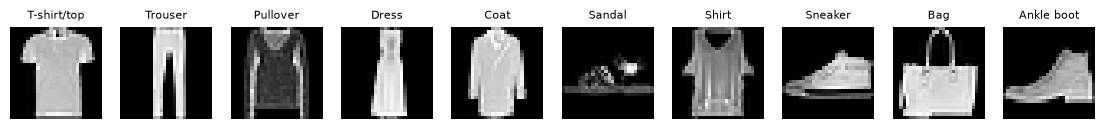

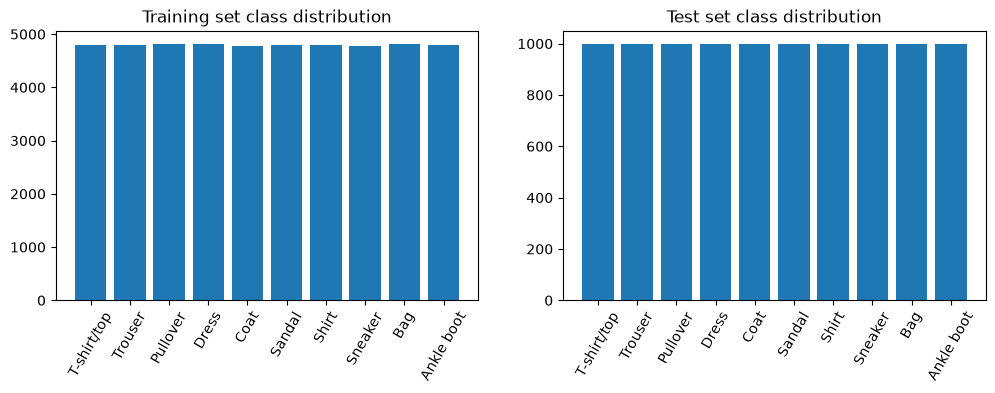

In [ ]:
class_names = temp_train.classes
print(class_names)

# one example of every class (unnormalized, so the images look natural)
fig, axes = plt.subplots(1, 10, figsize = (14, 2))
for c in range(10):
  i = np.where(y_train == c)[0][0]
  axes[c].imshow(X_train_raw[i].reshape(28, 28), cmap = 'gray')
  axes[c].set_title(class_names[c], fontsize = 8)
  axes[c].axis('off')
plt.show()

# class distribution plot for the "Datasets" section of the report
fig, axes = plt.subplots(1, 2, figsize = (12, 3.5))
axes[0].bar(class_names, np.bincount(y_train, minlength = 10))
axes[0].set_title('Training set class distribution')
axes[0].tick_params(axis = 'x', rotation = 60)
axes[1].bar(class_names, np.bincount(y_test, minlength = 10))
axes[1].set_title('Test set class distribution')
axes[1].tick_params(axis = 'x', rotation = 60)
plt.show()

All 10 classes have about 4,800 training images and exactly 1,000 test images, so the data is balanced and accuracy is a fair metric. No class reweighting is needed.

# Task 2: Implement a Multilayer Perceptron

In [ ]:
# helper functions
def relu(a):
  return np.maximum(0, a)

def relu_grad(a):
  return (a > 0).astype(float)   # a > 0, slope = 1 otherwise = 0

# tanh and its gradient (Q2)
def tanh(a):
  return np.tanh(a)

def tanh_grad(a):
  return 1 - np.tanh(a) ** 2

# Leaky-ReLU and its gradient (Q2)
def leaky_relu(a, slope = 0.01):
  return np.where(a > 0, a, slope * a)

def leaky_relu_grad(a, slope = 0.01):
  return np.where(a > 0, 1.0, slope)   # a > 0, slope = 1 otherwise = 0.01

def softmax(logits):
  exp_logits = np.exp(logits - np.max(logits, axis = 1, keepdims = True))
  return exp_logits / np.sum(exp_logits, axis = 1, keepdims = True)

def one_hot(y, c):
  return np.eye(c)[y]

def evaluate_acc(true, target):
  return np.sum(true == target) / len(true)

## MLP class

In [ ]:
class MLP:
  def __init__(self, activation, activation_grad, nhidden_layers, hidden_units,
               input_dim = 784, num_classes = 10,
               l1 = 0.0, l2 = 0.0):                  # l1, l2: regularization strengths (Q3), 0 = none
    self.activation = activation
    self.activation_grad = activation_grad
    assert nhidden_layers == len(hidden_units)
    self.l1 = l1
    self.l2 = l2

    # size of every layer
    size = [input_dim] + hidden_units + [num_classes]

    # weight matrix + bias between neighbouring layers (He initialization)
    self.weights = []
    self.biases = []
    for i in range(len(size) - 1):
      dim_in = size[i]
      dim_out = size[i + 1]
      W = np.random.randn(dim_in, dim_out) * np.sqrt(2 / dim_in)
      b = np.zeros(dim_out)
      self.weights.append(W)
      self.biases.append(b)

  def forward(self, X):
    a_list = []
    z_list = [X]

    z = X
    for l in range(len(self.weights)):
      a = np.dot(z, self.weights[l]) + self.biases[l]   # inputs * weights
      if l < len(self.weights) - 1:                     # hidden layer
        z = self.activation(a)
      else:                                             # last layer
        z = softmax(a)
      a_list.append(a)
      z_list.append(z)

    return a_list, z_list

  def backward(self, X, y):
    N = X.shape[0]

    # forward pass
    a_list, z_list = self.forward(X)
    yh = z_list[-1]                     # predicted probabilities

    dW = [None] * len(self.weights)
    db = [None] * len(self.weights)

    dy = yh - y                         # gradient of softmax + cross-entropy

    for l in reversed(range(len(self.weights))):
      dW[l] = np.dot(z_list[l].T, dy) / N
      # regularization gradient, only on weights (not biases)
      #   L2 penalty (l2/2)*sum(W^2) -> gradient l2*W
      #   L1 penalty  l1*sum(|W|)    -> gradient l1*sign(W)
      dW[l] += self.l2 * self.weights[l] + self.l1 * np.sign(self.weights[l])
      db[l] = np.sum(dy, axis = 0) / N  # average error per unit
      if l > 0:
        dz = np.dot(dy, self.weights[l].T)
        dy = dz * self.activation_grad(a_list[l - 1])

    return dW, db

  def fit(self, X, y, lr, epochs, batch_size,
          X_eval = None, y_eval = None):              # optional eval set (val or test), for the curves
    N = X.shape[0]
    Y = one_hot(y, 10)
    self.train_acc = []
    self.eval_acc = []
    self.train_time = 0                             # time of the gradient steps only (not the evaluation)

    for epoch in range(epochs):
      epoch_start = time.time()
      perm = np.random.permutation(N)
      for start in range(0, N, batch_size):         # mini-batch SGD
        i = perm[start:start + batch_size]

        dW, db = self.backward(X[i], Y[i])          # gradient of the current batch

        for l in range(len(self.weights)):
          self.weights[l] -= lr * dW[l]
          self.biases[l] -= lr * db[l]
      self.train_time += time.time() - epoch_start

      self.train_acc.append(evaluate_acc(y, self.predict(X)))
      if X_eval is not None:
        self.eval_acc.append(evaluate_acc(y_eval, self.predict(X_eval)))

    return self

  def predict(self, X):
    a_list, z_list = self.forward(X)   # predicted class for each input with the highest probability
    return np.argmax(z_list[-1], axis = 1)

## Gradient check

We compare the gradients from `backward()` with numerical gradients
$\frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$ on a tiny network, **with L1 and L2 regularization switched on**,
so the regularization gradients are checked too.
We use tanh here, because ReLU has a kink at 0 where the numerical gradient is not reliable.

In [ ]:
def cost(model, X, Y):
  yh = model.forward(X)[1][-1]                              # predicted probabilities
  loss = -np.sum(Y * np.log(yh + 1e-12)) / X.shape[0]       # cross-entropy
  for W in model.weights:                                   # + regularization (weights only)
    loss += model.l2 / 2 * np.sum(W ** 2) + model.l1 * np.sum(np.abs(W))
  return loss

np.random.seed(0)
check = MLP(tanh, tanh_grad, 1, [5], input_dim = 4, num_classes = 3, l1 = 0.01, l2 = 0.01)
X_check = np.random.randn(6, 4)
Y_check = one_hot(np.random.randint(0, 3, 6), 3)
dW, db = check.backward(X_check, Y_check)

eps = 1e-6
max_diff = 0
for l in range(len(check.weights)):
  for params, grads in [(check.weights[l], dW[l]), (check.biases[l], db[l])]:
    for idx in np.ndindex(params.shape):   # every single weight / bias
      old = params[idx]
      params[idx] = old + eps
      loss_plus = cost(check, X_check, Y_check)
      params[idx] = old - eps
      loss_minus = cost(check, X_check, Y_check)
      params[idx] = old
      numerical = (loss_plus - loss_minus) / (2 * eps)
      max_diff = max(max_diff, abs(numerical - grads[idx]))

print('largest difference between backprop and numerical gradient:', max_diff)   # should be ~1e-8 or smaller

largest difference between backprop and numerical gradient: 1.5850160073327402e-10


The largest difference between backpropagation and numerical gradients is 1.6e-10, so our backward pass, including the L1 and L2 terms, is correct.

# Task 3: Run the experiments and report

## Common settings

`results` collects the test accuracy, training time and per-epoch accuracies of **every** model in this notebook
(the CNNs and ResNet in Part 2 are added to the same dictionary), so one table and one plotting function work for all.

In [ ]:
TUNING_EPOCHS = 2 if QUICK_RUN else 5   # shorter runs, only for choosing hyperparameters on the validation set

if QUICK_RUN:
  X_train, y_train, X_train_raw = X_train[:5000], y_train[:5000], X_train_raw[:5000]
  X_val, y_val, X_val_raw = X_val[:1000], y_val[:1000], X_val_raw[:1000]
  X_test, y_test, X_test_raw = X_test[:1000], y_test[:1000], X_test_raw[:1000]

results = {}      # model name -> {'test_acc', 'time', 'history': {'train_acc': [...], 'eval_acc': [...]}}
mlp_models = {}   # model name -> trained MLP (used by the extra experiments)

## Plotting and table functions

* `plot_histories`: train accuracy (dashed) and test accuracy (solid) per epoch.
* `plot_test_acc`: bar chart of the final test accuracy.
* `print_table`: test accuracy and training time.

All three are reused for every model in the notebook.

In [ ]:
def plot_histories(names, title, eval_name = 'test'):
  # names: model names in `results`. Same colour for one model: train dashed, eval solid.
  plt.figure(figsize = (7, 4))
  for i, name in enumerate(names):
    hist = results[name]['history']
    epochs = np.arange(1, len(hist['train_acc']) + 1)
    plt.plot(epochs, hist['train_acc'], '--', color = f'C{i}', label = f'{name} (train)')
    plt.plot(epochs, hist['eval_acc'], '-', color = f'C{i}', label = f'{name} ({eval_name})')
  plt.xlabel('epoch')
  plt.ylabel('accuracy')
  plt.title(title)
  plt.legend(fontsize = 8)
  plt.grid(alpha = .3)
  plt.show()


def plot_test_acc(names, title):
  accs = [results[n]['test_acc'] for n in names]
  plt.figure(figsize = (8, 0.4 * len(names) + 1))
  plt.barh(names, accs)
  for i, acc in enumerate(accs):
    plt.text(acc + 0.005, i, f'{acc:.3f}', va = 'center', fontsize = 8)
  plt.xlabel('test accuracy')
  plt.xlim(0, 1.05)
  plt.gca().invert_yaxis()
  plt.title(title)
  plt.grid(axis = 'x', alpha = .3)
  plt.show()


def print_table(names):
  print(f'{"model":45s} {"test acc":>9s} {"time (s)":>9s}')
  for name in names:
    print(f'{name:45s} {results[name]["test_acc"]:9.4f} {results[name]["time"]:9.1f}')

## Choosing the learning rate (validation set)

We try a few learning rates for the 2-hidden-layer ReLU MLP (batch size 64) and keep the one with the best
validation accuracy after the last tuning epoch.

lr = 0.005: validation accuracy per epoch [0.8228 0.8402 0.8544 0.8599 0.8617]
lr = 0.01: validation accuracy per epoch [0.8429 0.8577 0.8651 0.8634 0.8743]
lr = 0.05: validation accuracy per epoch [0.8563 0.8658 0.8783 0.8801 0.8861]
lr = 0.1: validation accuracy per epoch [0.8598 0.8583 0.8868 0.8866 0.8742]


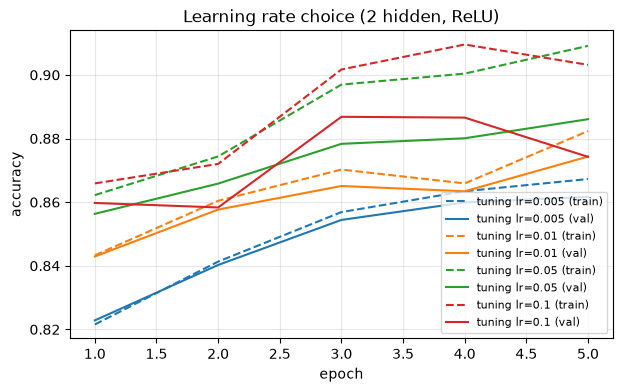

chosen learning rate: 0.05


In [ ]:
np.random.seed(0)
lr_candidates = [0.005, 0.01, 0.05, 0.1]
for lr in lr_candidates:
  model = MLP(relu, relu_grad, 2, [256, 256])
  model.fit(X_train, y_train, lr, TUNING_EPOCHS, 64, X_eval = X_val, y_eval = y_val)
  results[f'tuning lr={lr}'] = {'history': {'train_acc': model.train_acc, 'eval_acc': model.eval_acc}}
  print(f'lr = {lr}: validation accuracy per epoch', np.round(model.eval_acc, 4))

plot_histories([f'tuning lr={lr}' for lr in lr_candidates], 'Learning rate choice (2 hidden, ReLU)', eval_name = 'val')

LEARNING_RATE = max(lr_candidates, key = lambda lr: results[f'tuning lr={lr}']['history']['eval_acc'][-1])
for lr in lr_candidates:
  del results[f'tuning lr={lr}']   # tuning runs are not part of the final results table
print('chosen learning rate:', LEARNING_RATE)

A learning rate of 0.05 gives the best validation accuracy after 5 epochs (88.6%). The rate 0.1 peaks earlier (88.7% at epoch 3) but then drops to 87.4%, a sign that its steps are too large to train stably. The rates 0.005 and 0.01 are still improving slowly.

## Choosing the batch size (validation set)

Same model, the chosen learning rate, and the same number of epochs. A smaller batch gives more (noisier)
gradient steps per epoch but is slower, because NumPy works less efficiently on small matrices.
We therefore also record the training time.

batch size 32: validation accuracy 0.8826, time 16.5s
batch size 64: validation accuracy 0.8830, time 9.3s
batch size 128: validation accuracy 0.8815, time 5.5s
batch size 256: validation accuracy 0.8610, time 3.6s


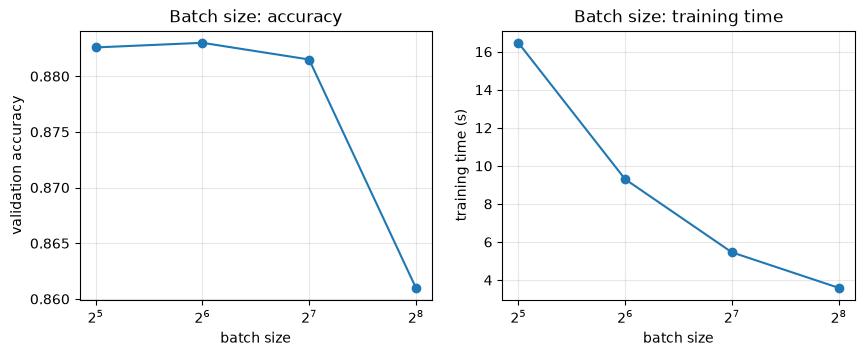

chosen batch size: 64


In [ ]:
np.random.seed(0)
batch_candidates = [32, 64, 128, 256]
val_acc_batch = []
time_batch = []
for bs in batch_candidates:
  model = MLP(relu, relu_grad, 2, [256, 256])
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, bs, X_eval = X_val, y_eval = y_val)
  time_batch.append(model.train_time)
  val_acc_batch.append(model.eval_acc[-1])
  print(f'batch size {bs}: validation accuracy {val_acc_batch[-1]:.4f}, time {time_batch[-1]:.1f}s')

fig, axes = plt.subplots(1, 2, figsize = (10, 3.5))
axes[0].plot(batch_candidates, val_acc_batch, 'o-')
axes[0].set_xscale('log', base = 2); axes[0].set_xlabel('batch size'); axes[0].set_ylabel('validation accuracy')
axes[0].set_title('Batch size: accuracy'); axes[0].grid(alpha = .3)
axes[1].plot(batch_candidates, time_batch, 'o-')
axes[1].set_xscale('log', base = 2); axes[1].set_xlabel('batch size'); axes[1].set_ylabel('training time (s)')
axes[1].set_title('Batch size: training time'); axes[1].grid(alpha = .3)
plt.show()

BATCH_SIZE = batch_candidates[int(np.argmax(val_acc_batch))]
print('chosen batch size:', BATCH_SIZE)

Batch sizes 32, 64 and 128 reach the same validation accuracy (88.2–88.3%), while 256 drops to 86.1% because it makes 4× fewer updates in the same 5 epochs. Larger batches are faster (3.6 s for 256 vs. 16.5 s for 32). We keep 64, the most accurate, and 128 would be a nearly equal, faster alternative.

## Choosing the number of epochs (validation set)

We train the 2-hidden-layer ReLU MLP for a long time with the chosen learning rate and batch size and keep the
number of epochs with the best validation accuracy. The gap between the training and validation curves also shows
when the MLP starts to overfit.

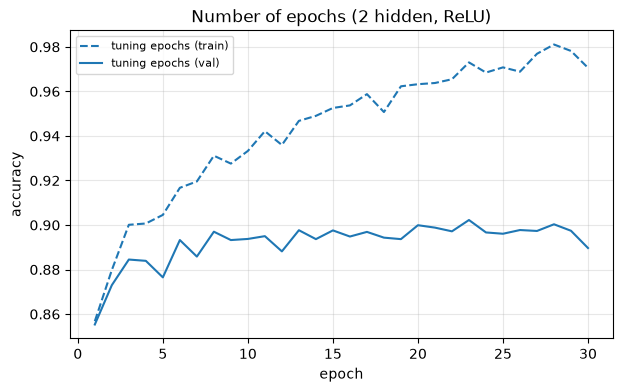

chosen number of epochs: 23


In [ ]:
MAX_EPOCHS = 2 if QUICK_RUN else 30
np.random.seed(0)
model = MLP(relu, relu_grad, 2, [256, 256])
model.fit(X_train, y_train, LEARNING_RATE, MAX_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
results['tuning epochs'] = {'history': {'train_acc': model.train_acc, 'eval_acc': model.eval_acc}}
plot_histories(['tuning epochs'], 'Number of epochs (2 hidden, ReLU)', eval_name = 'val')
del results['tuning epochs']

EPOCHS = int(np.argmax(model.eval_acc)) + 1
print('chosen number of epochs:', EPOCHS)

Validation accuracy rises quickly for about 10 epochs, then plateaus around 89.5-90% and peaks at 90.2% at epoch 23, while training accuracy keeps climbing to about 98%. The growing gap is overfitting: after roughly 10 epochs, extra training mostly memorizes the training set. We use the best epoch, 23.

## Training function

`run_experiment` trains one MLP with our `fit()` using the learning rate, batch size and number of epochs chosen above,
and stores the test accuracy, training time and per-epoch accuracies in `results`.
The training time only counts the gradient steps (not the accuracy computed after every epoch), exactly like for the
CNNs in Part 2.

In [ ]:
def run_experiment(name, model, X_tr, y_tr, X_te, y_te, lr = None, epochs = EPOCHS):
  if lr is None:
    lr = LEARNING_RATE
  print(f'===== {name} =====')
  model.fit(X_tr, y_tr, lr, epochs, BATCH_SIZE, X_eval = X_te, y_eval = y_te)
  train_time = model.train_time   # only the gradient steps, measured the same way as for the CNNs
  test_acc = evaluate_acc(y_te, model.predict(X_te))
  print(f'--> test accuracy {test_acc:.4f}, training time {train_time:.1f}s\n')
  results[name] = {'test_acc': test_acc, 'time': train_time,
                   'history': {'train_acc': model.train_acc, 'eval_acc': model.eval_acc}}
  mlp_models[name] = model
  return model

# Part 1: MLP experiments (Q1–Q5)

## Q1: Effect of non-linearity and depth

1. no hidden layer (this is multinomial logistic regression),
2. one hidden layer with 256 ReLU units,
3. two hidden layers with 256 ReLU units each.

All of them end with a softmax layer.

===== 0 hidden =====
--> test accuracy 0.8348, training time 1.9s

===== 1 hidden ReLU =====
--> test accuracy 0.8858, training time 34.9s

===== 2 hidden ReLU =====
--> test accuracy 0.8789, training time 42.5s



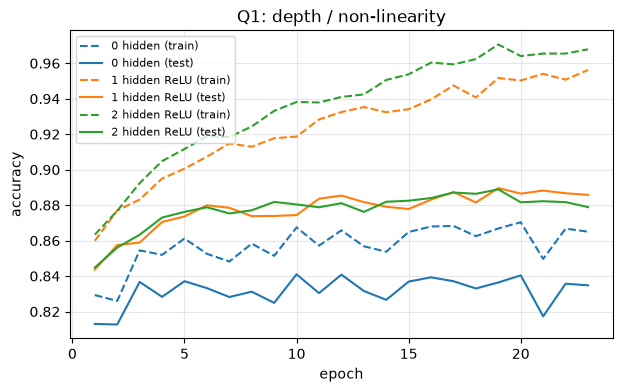

In [ ]:
np.random.seed(1)
run_experiment('0 hidden', MLP(relu, relu_grad, 0, []), X_train, y_train, X_test, y_test)
run_experiment('1 hidden ReLU', MLP(relu, relu_grad, 1, [256]), X_train, y_train, X_test, y_test)
run_experiment('2 hidden ReLU', MLP(relu, relu_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)

plot_histories(['0 hidden', '1 hidden ReLU', '2 hidden ReLU'], 'Q1: depth / non-linearity')

One ReLU hidden layer raises test accuracy from 83.5% to 88.6% (+5.1 points), but a second layer does not help (87.9%). The linear model underfits, with even its training accuracy around 86%. Both hidden-layer models fit the training set to 96-97% but stall near 88% on the test set, so the extra depth adds capacity the task does not need and mainly increases overfitting and training time (42.5 s vs. 34.9 s). The gain from non-linearity is expected. The lack of gain from depth is plausible for small 28*28 images, and the 0.7-point difference is within the epoch-to-epoch noise of the curves.

## Q2: Activation functions (tanh and Leaky-ReLU vs. ReLU)

Same 2-hidden-layer architecture, only the activation changes.

===== 2 hidden tanh =====
--> test accuracy 0.8862, training time 45.4s

===== 2 hidden LeakyReLU =====
--> test accuracy 0.8808, training time 45.9s



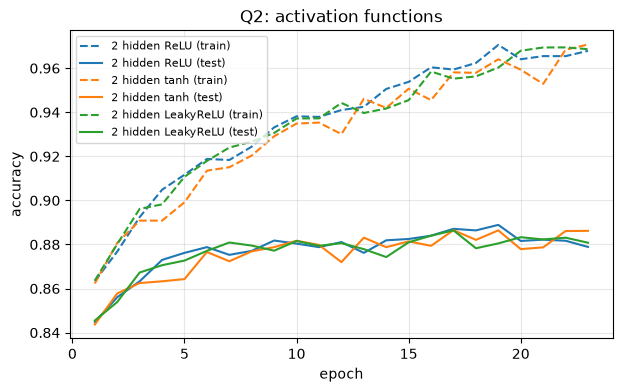

In [ ]:
np.random.seed(2)
run_experiment('2 hidden tanh', MLP(tanh, tanh_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)
run_experiment('2 hidden LeakyReLU', MLP(leaky_relu, leaky_relu_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)

plot_histories(['2 hidden ReLU', '2 hidden tanh', '2 hidden LeakyReLU'], 'Q2: activation functions')

Tanh (88.6%), Leaky-ReLU (88.1%) and ReLU (87.9%) are within 0.7 points, and their curves overlap throughout training. This is within run-to-run variation (the ranking changed between our runs), so no activation is clearly better here. With only two hidden layers and normalized inputs, tanh does not saturate badly and ReLU units rarely "die", which removes the usual advantage of Leaky-ReLU. We use He initialization, which is designed for ReLU-type units, while Xavier initialization is the usual choice for tanh.

## Q3: L1 and L2 regularization

We first choose the strength $\lambda$ for each type on the **validation** set ($\lambda = 0$ is the
unregularized baseline), then train the final models.

lambda = 0: validation accuracy L1 0.8858, L2 0.8879
lambda = 1e-05: validation accuracy L1 0.8842, L2 0.8807
lambda = 0.0001: validation accuracy L1 0.8831, L2 0.8904
lambda = 0.001: validation accuracy L1 0.8357, L2 0.8826
lambda = 0.01: validation accuracy L1 0.7544, L2 0.8653
lambda = 0.1: validation accuracy L1 0.0982, L2 0.7563


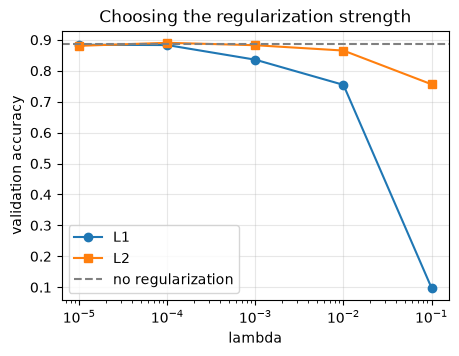

chosen lambda for L1: 1e-05   for L2: 0.0001


In [ ]:
np.random.seed(3)
lambda_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
val_acc_l1 = []
val_acc_l2 = []
for lam in lambda_candidates:
  model = MLP(relu, relu_grad, 2, [256, 256], l1 = lam)
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  val_acc_l1.append(model.eval_acc[-1])

  model = MLP(relu, relu_grad, 2, [256, 256], l2 = lam)
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  val_acc_l2.append(model.eval_acc[-1])
  print(f'lambda = {lam}: validation accuracy L1 {val_acc_l1[-1]:.4f}, L2 {val_acc_l2[-1]:.4f}')

nonzero = lambda_candidates[1:]
plt.figure(figsize = (5, 3.5))
plt.semilogx(nonzero, val_acc_l1[1:], 'o-', label = 'L1')
plt.semilogx(nonzero, val_acc_l2[1:], 's-', label = 'L2')
plt.axhline(val_acc_l1[0], color = 'gray', linestyle = '--', label = 'no regularization')   # lambda = 0 baseline
plt.xlabel('lambda'); plt.ylabel('validation accuracy'); plt.legend(); plt.grid(alpha = .3)
plt.title('Choosing the regularization strength')
plt.show()

# choose among the nonzero lambdas, so the L1 / L2 models are actually regularized
best_l1 = nonzero[int(np.argmax(val_acc_l1[1:]))]
best_l2 = nonzero[int(np.argmax(val_acc_l2[1:]))]
print('chosen lambda for L1:', best_l1, '  for L2:', best_l2)

Only small penalties keep validation accuracy close to the unregularized model, so we choose λ = 1e-5 for L1 and λ = 1e-4 for L2. L1 hurts much sooner than L2: at λ = 1e-3, validation accuracy is 83.6% with L1 vs. 88.3% with L2, and at λ = 0.1 L1 collapses to chance (9.8%). L2 shrinks each weight in proportion to its size, whereas L1 pushes every weight towards zero by the same amount, so a large λ wipes out most weights.

===== 2 hidden ReLU + L1 =====
--> test accuracy 0.8865, training time 44.1s

===== 2 hidden ReLU + L2 =====
--> test accuracy 0.8849, training time 44.4s



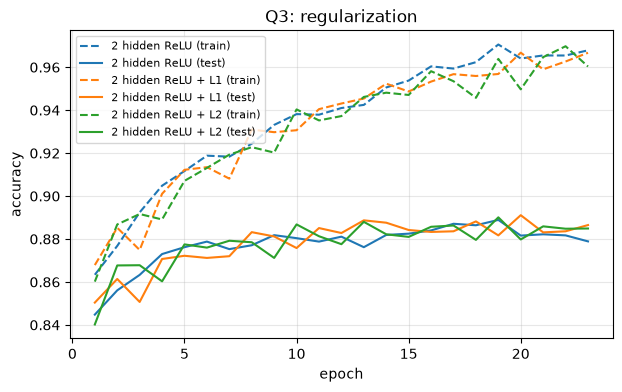

In [ ]:
np.random.seed(30)
run_experiment('2 hidden ReLU + L1', MLP(relu, relu_grad, 2, [256, 256], l1 = best_l1), X_train, y_train, X_test, y_test)
run_experiment('2 hidden ReLU + L2', MLP(relu, relu_grad, 2, [256, 256], l2 = best_l2), X_train, y_train, X_test, y_test)

plot_histories(['2 hidden ReLU', '2 hidden ReLU + L1', '2 hidden ReLU + L2'], 'Q3: regularization')

L1 (88.7%) and L2 (88.5%) slightly beat the unregularized model (87.9%), and L1 gives our best MLP. The gains are small, and the curves show that all three models still reach about 96-97% training accuracy, so these weak penalties barely reduce overfitting. Stronger penalties, which would close the gap, cost validation accuracy (previous cell).

### Extra 1: what do L1 and L2 do to the weights?

L2 adds $\lambda W$ to the gradient, shrinking each weight in proportion to its size. L1 adds $\lambda\,\mathrm{sign}(W)$, a constant push towards 0 that drives small weights to near zero, making the weights sparse. Since SGD makes L1 weights oscillate around 0 rather than reach it exactly, we count $|w| < 10^{-3}$ as zero. We examine the first layer (784 × 256 weights), which connects directly to the pixels.


no regularization         mean |w| = 0.0459,  fraction of weights with |w| < 1e-3: 0.014
L1 (lambda = 1e-05)       mean |w| = 0.0389,  fraction of weights with |w| < 1e-3: 0.050
L2 (lambda = 0.0001)      mean |w| = 0.0426,  fraction of weights with |w| < 1e-3: 0.015


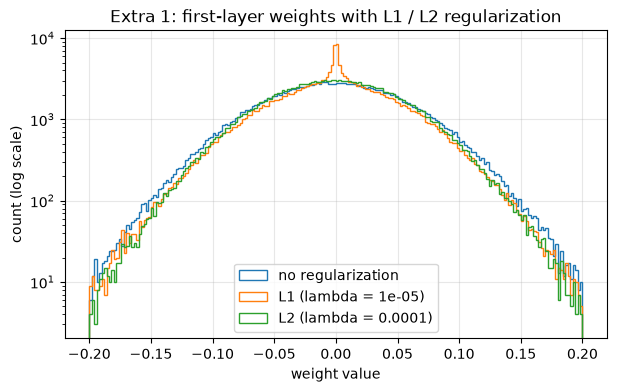

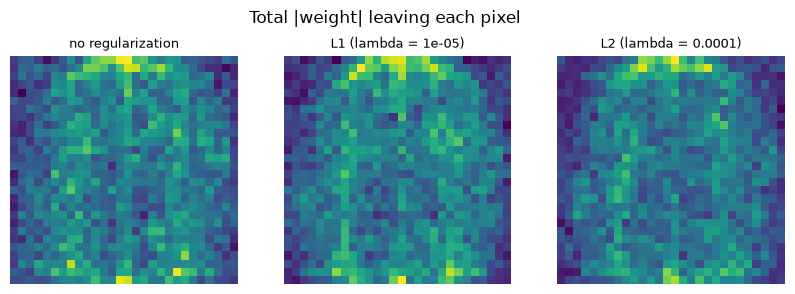

In [ ]:
weight_models = {'no regularization': mlp_models['2 hidden ReLU'],
                 f'L1 (lambda = {best_l1})': mlp_models['2 hidden ReLU + L1'],
                 f'L2 (lambda = {best_l2})': mlp_models['2 hidden ReLU + L2']}

plt.figure(figsize = (7, 4))
for label, model in weight_models.items():
  W = model.weights[0].ravel()   # first layer weights
  plt.hist(W, bins = 200, range = (-0.2, 0.2), histtype = 'step', label = label)
  print(f'{label:25s} mean |w| = {np.mean(np.abs(W)):.4f},  fraction of weights with |w| < 1e-3: {np.mean(np.abs(W) < 1e-3):.3f}')
plt.yscale('log')
plt.xlabel('weight value'); plt.ylabel('count (log scale)')
plt.title('Extra 1: first-layer weights with L1 / L2 regularization')
plt.legend(); plt.grid(alpha = .3)
plt.show()

# which pixels does the L1 model still use? (sum of |weights| leaving every pixel)
fig, axes = plt.subplots(1, 3, figsize = (10, 3.3))
for ax, (label, model) in zip(axes, weight_models.items()):
  ax.imshow(np.abs(model.weights[0]).sum(axis = 1).reshape(28, 28), cmap = 'viridis')
  ax.set_title(label, fontsize = 9); ax.axis('off')
plt.suptitle('Total |weight| leaving each pixel')
plt.show()

L1 makes the first layer sparser: the share of near-zero weights rises from 1.4% to 5.0% and the mean |w| falls from 0.046 to 0.039. L2 barely changes either number (1.5%, 0.043), because it shrinks all weights proportionally instead of zeroing them. The pixel maps show that both penalties mostly reduce the weights leaving the border pixels, which are background in almost every image and so carry little information.

## Q4: Training on unnormalized images

Same 2-hidden-layer ReLU MLP on the raw pixel values 0..255 (`X_train_raw` from Task 1), with the same learning rate.
The inputs are ~255× larger, so the first-layer pre-activations and gradients are much larger and the same step size
can blow up training (if the weights overflow, every prediction becomes the same class and the accuracy is 10%).
**Extra:** we also try a much smaller learning rate to see whether the step size is the only problem.

===== 2 hidden ReLU, unnormalized =====
--> test accuracy 0.1000, training time 30.2s

===== 2 hidden ReLU, unnormalized, lr=1e-5 =====
--> test accuracy 0.7829, training time 40.9s



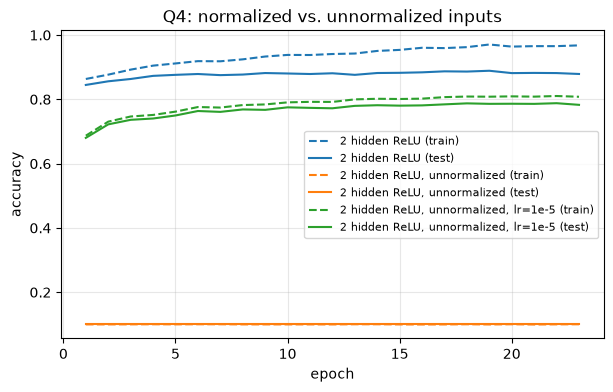

In [ ]:
np.random.seed(4)
run_experiment('2 hidden ReLU, unnormalized', MLP(relu, relu_grad, 2, [256, 256]),
               X_train_raw, y_train, X_test_raw, y_test)
run_experiment('2 hidden ReLU, unnormalized, lr=1e-5', MLP(relu, relu_grad, 2, [256, 256]),
               X_train_raw, y_train, X_test_raw, y_test, lr = 1e-5)

plot_histories(['2 hidden ReLU', '2 hidden ReLU, unnormalized', '2 hidden ReLU, unnormalized, lr=1e-5'],
               'Q4: normalized vs. unnormalized inputs')

On raw pixel values (0-255) with the same learning rate, training diverges immediately: the model predicts a single class and gets exactly chance accuracy (10.0%). The inputs are about 255x larger than after normalization and all positive, so the first-layer pre-activations and gradients are huge, and a step size of 0.05 makes the weights blow up. A 5000x smaller learning rate (1e-5) trains stably but reaches only 78.3%, about 10 points below the normalized model, and is still improving slowly. One learning rate cannot suit both the first layer, whose gradients scale with the large inputs, and the later layers. Normalization fixes this by putting all inputs on a common scale centred at zero.

## Comparison of the 8 MLPs from Q1–Q4

model                                          test acc  time (s)
0 hidden                                         0.8348       1.9
1 hidden ReLU                                    0.8858      34.9
2 hidden ReLU                                    0.8789      42.5
2 hidden tanh                                    0.8862      45.4
2 hidden LeakyReLU                               0.8808      45.9
2 hidden ReLU + L1                               0.8865      44.1
2 hidden ReLU + L2                               0.8849      44.4
2 hidden ReLU, unnormalized                      0.1000      30.2


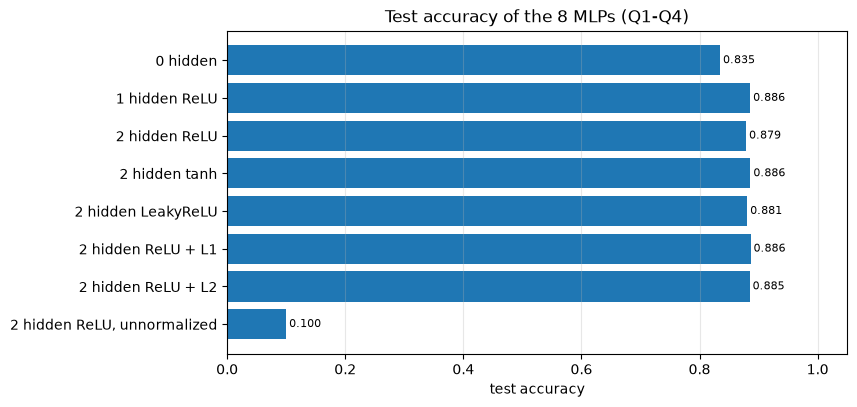

In [ ]:
eight_mlps = ['0 hidden', '1 hidden ReLU', '2 hidden ReLU', '2 hidden tanh', '2 hidden LeakyReLU',
              '2 hidden ReLU + L1', '2 hidden ReLU + L2', '2 hidden ReLU, unnormalized']
print_table(eight_mlps)
plot_test_acc(eight_mlps, 'Test accuracy of the 8 MLPs (Q1-Q4)')

Every normalized MLP with a hidden layer lands within one point of the others (87.9-88.7%), whatever its depth, activation or regularization. The two choices that really matter are non-linearity (+5 points over the linear model) and input normalization (the difference between 10% and 88%).

## Q5: Data augmentation

We retrain the L2-regularized MLP from Q3 on augmented data, built with `transforms.Compose()`: random horizontal flips (a flipped shirt is still a shirt), rotations up to ±10° and shifts up to 10%. Since our MLP is in NumPy, we add one augmented copy of each of the 48k training images and train on both; validation and test images are not augmented. The same `augmentation` and `aug_transform` are reused in Q7–Q9.


training set with augmentation: (96000, 784)


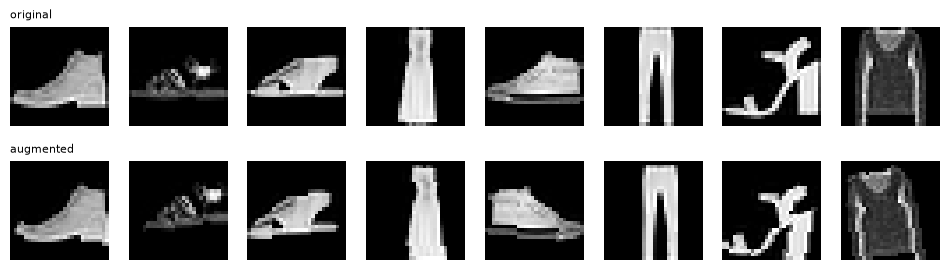

In [ ]:
augmentation = [transforms.RandomHorizontalFlip(),
                transforms.RandomAffine(degrees = 10, translate = (0.1, 0.1))]

# augmentation, then the same ToTensor + Normalize as train_transform in Task 1
aug_transform = transforms.Compose(augmentation + [transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
aug_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=aug_transform)

# only the images already in the training set (no validation image leaks in)
aug_data = torch.utils.data.Subset(aug_dataset, train_data.indices[:len(X_train)])
X_aug, y_aug = to_numpy(aug_data)          # each image gets a new random flip / rotation / shift
assert np.all(y_aug == y_train)

X_train_with_aug = np.concatenate([X_train, X_aug])
y_train_with_aug = np.concatenate([y_train, y_aug])
print('training set with augmentation:', X_train_with_aug.shape)

# a few original images and their augmented copies
fig, axes = plt.subplots(2, 8, figsize = (12, 3.2))
for i in range(8):
  axes[0, i].imshow(X_train[i].reshape(28, 28), cmap = 'gray'); axes[0, i].axis('off')
  axes[1, i].imshow(X_aug[i].reshape(28, 28), cmap = 'gray'); axes[1, i].axis('off')
axes[0, 0].set_title('original', fontsize = 8, loc = 'left')
axes[1, 0].set_title('augmented', fontsize = 8, loc = 'left')
plt.show()

===== 2 hidden ReLU + L2 + augmentation =====
--> test accuracy 0.8795, training time 85.6s



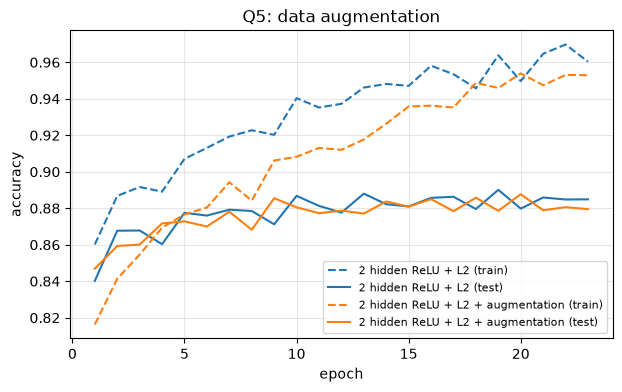

In [ ]:
np.random.seed(5)
run_experiment('2 hidden ReLU + L2 + augmentation', MLP(relu, relu_grad, 2, [256, 256], l2 = best_l2),
               X_train_with_aug, y_train_with_aug, X_test, y_test)

plot_histories(['2 hidden ReLU + L2', '2 hidden ReLU + L2 + augmentation'], 'Q5: data augmentation')

Augmentation lowers test accuracy slightly, from 88.5% to 88.0%, and nearly doubles training time (85.6 s vs. 44.4 s) because the training set is twice as large. It does reduce overfitting: final training accuracy is lower (about 95% vs. 96–97%), so the train–test gap narrows.

- **Benefits:** augmentation teaches invariances that real test data has, such as small shifts and rotations, and acts as a regularizer.
- **Drawbacks:** it costs more computation, and it helps an MLP less than a CNN. An MLP has no notion of nearby pixels, so each shifted image looks like a new input that it must learn separately. We also make only one fixed augmented copy per image, instead of new random copies every epoch.
- **When it hurts:** augmentation is harmful when it changes the label or creates images that never occur at test time. Examples are rotating handwritten digits (a 6 becomes a 9), flipping text or road signs, flipping medical images where left and right matter, and vertically flipping FashionMNIST items, which are always upright (tested in Extra 2).

## Optional: width of the hidden layers (validation set)

How many units per hidden layer does the 2-hidden-layer ReLU MLP need? 256 is the size the assignment asks for;
here we check whether narrower or wider layers would help.

32 units per layer: validation accuracy 0.8757
64 units per layer: validation accuracy 0.8712
128 units per layer: validation accuracy 0.8752
256 units per layer: validation accuracy 0.8697
512 units per layer: validation accuracy 0.8888


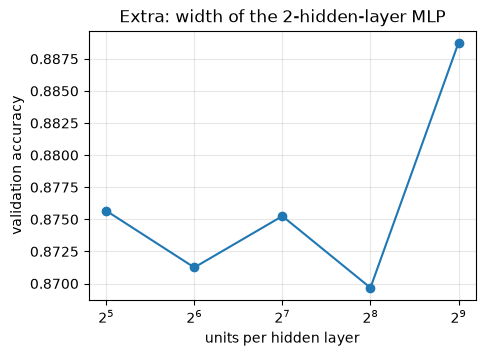

In [ ]:
np.random.seed(6)
width_candidates = [32, 64, 128, 256, 512]
val_acc_width = []
for width in width_candidates:
  model = MLP(relu, relu_grad, 2, [width, width])
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  val_acc_width.append(model.eval_acc[-1])
  print(f'{width} units per layer: validation accuracy {val_acc_width[-1]:.4f}')

plt.figure(figsize = (5, 3.5))
plt.plot(width_candidates, val_acc_width, 'o-')
plt.xscale('log', base = 2)
plt.xlabel('units per hidden layer'); plt.ylabel('validation accuracy'); plt.grid(alpha = .3)
plt.title('Optional: width of the 2-hidden-layer MLP')
plt.show()

After 5 epochs, widths from 32 to 256 units all reach 87.0-87.6% validation accuracy with no clear trend, and 512 units is best at 88.9%. Even 32 units per layer reach about 87.5%, so the MLP's accuracy is not limited by its width. The differences between 32 and 256 units are within the noise of short runs. We keep 256 units, as the assignment specifies.

## Summary of the MLPs

In [ ]:
mlp_names = list(results.keys())   # every model trained so far is an MLP
best_mlp = max(mlp_names, key = lambda n: results[n]['test_acc'])
print_table(mlp_names)
print('\nbest MLP:', best_mlp)

model                                          test acc  time (s)
0 hidden                                         0.8348       1.9
1 hidden ReLU                                    0.8858      34.9
2 hidden ReLU                                    0.8789      42.5
2 hidden tanh                                    0.8862      45.4
2 hidden LeakyReLU                               0.8808      45.9
2 hidden ReLU + L1                               0.8865      44.1
2 hidden ReLU + L2                               0.8849      44.4
2 hidden ReLU, unnormalized                      0.1000      30.2
2 hidden ReLU, unnormalized, lr=1e-5             0.7829      40.9
2 hidden ReLU + L2 + augmentation                0.8795      85.6

best MLP: 2 hidden ReLU + L1


The best MLP is the 2-hidden-layer ReLU network with L1 regularization (88.7% test accuracy). We use it as the reference for the CNN and the pre-trained model.

# Part 2: CNN and pre-trained model (Q6–Q9)

In [ ]:
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision

torch.manual_seed(0)
if torch.cuda.is_available():
  device = torch.device('cuda')
elif torch.backends.mps.is_available():      # Apple Silicon GPU
  device = torch.device('mps')
else:
  device = torch.device('cpu')
print(f'Using device: {device}')

Using device: mps


## Data loaders

`make_loaders` builds FashionMNIST loaders for any transforms, using the same split as Part 1:

* `trainloader`: shuffled training images with the training transform (e.g. augmentation),
* `train_evalloader`: 10,000 non-augmented training images, used only to measure training accuracy,
`valloader`, `testloader`: never augmented.


In [ ]:
def make_loaders(train_tf, eval_tf, batch_size = 64):
  # two copies of the training partition: one with the training transform, one with the evaluation transform
  train_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=train_tf)
  eval_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=eval_tf)
  test_full = datasets.FashionMNIST(root="./data", train=False, download=True, transform=eval_tf)

  train_idx = train_data.indices                # same split as Part 1 (Task 1), so the comparison is fair
  val_idx = val_data.indices
  test_idx = list(range(len(test_full)))
  if QUICK_RUN:
    train_idx, val_idx, test_idx = train_idx[:2000], val_idx[:500], test_idx[:500]

  trainloader = DataLoader(torch.utils.data.Subset(train_full, train_idx), batch_size = batch_size, shuffle = True, num_workers = 2)
  # train_idx is already in random order, so its first 10k images are a random sample of the training set
  train_evalloader = DataLoader(torch.utils.data.Subset(eval_full, train_idx[:10000]), batch_size = batch_size, shuffle = False, num_workers = 2)
  valloader = DataLoader(torch.utils.data.Subset(eval_full, val_idx), batch_size = batch_size, shuffle = False, num_workers = 2)
  testloader = DataLoader(torch.utils.data.Subset(test_full, test_idx), batch_size = batch_size, shuffle = False, num_workers = 2)
  return trainloader, train_evalloader, valloader, testloader

trainloader, train_evalloader, valloader, testloader = make_loaders(train_transform, train_transform)   # Task 1 normalization
trainloader_aug, _, _, _ = make_loaders(aug_transform, train_transform)                                 # Q5 augmentation
print('training batches:', len(trainloader), ' validation batches:', len(valloader), ' test batches:', len(testloader))

training batches: 750  validation batches: 188  test batches: 157


## Training and evaluation functions

The course notebook's training and test loops, written as functions. After each epoch we record training and evaluation accuracy in the MLP's `{'train_acc', 'eval_acc'}` format, so `results` and `plot_histories` work unchanged.

As for the MLP, training accuracy is measured after each epoch, in evaluation mode, on non-augmented images (`train_evalloader`). Averaging over mini-batches would mix weights from across the epoch and, with augmentation, score harder images than the test set. Training time counts only the gradient steps.

If `testloader` is given, test accuracy is also recorded each epoch, for the plots only; it is never used to choose hyperparameters.


In [ ]:
def predict_labels(model, loader):
  model.eval()
  true_labels = []
  predictions = []
  with torch.no_grad():
    for images, labels in loader:
      outputs = model(images.to(device))
      predictions.append(outputs.argmax(dim = 1).cpu().numpy())   # class with the highest score
      true_labels.append(labels.numpy())
  return np.concatenate(true_labels), np.concatenate(predictions)


def evaluate_accuracy(model, loader):
  true_labels, predictions = predict_labels(model, loader)
  return evaluate_acc(true_labels, predictions)   # Part 1 accuracy function


def train_model(model, trainloader, train_evalloader, evalloader, num_epochs = 5, lr = 0.01, testloader = None):
  criterion = nn.CrossEntropyLoss()
  # only parameters with requires_grad=True are trained (matters for the frozen pre-trained model)
  trainable = [p for p in model.parameters() if p.requires_grad]
  optimizer = optim.SGD(trainable, lr = lr, momentum = 0.9)

  history = {'train_acc': [], 'eval_acc': [], 'test_acc': []}
  train_time = 0
  for epoch in range(num_epochs):
    # ===== Training phase =====
    start = time.time()
    model.train()
    for images, labels in trainloader:
      images = images.to(device)
      labels = labels.to(device)

      optimizer.zero_grad()
      outputs = model(images)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()
    train_time += time.time() - start             # only the training phase counts as training time

    # ===== Evaluation phase =====
    history['train_acc'].append(evaluate_accuracy(model, train_evalloader))
    history['eval_acc'].append(evaluate_accuracy(model, evalloader))
    if testloader is not None:
      history['test_acc'].append(evaluate_accuracy(model, testloader))
    print(f'Epoch [{epoch + 1}/{num_epochs}] - train acc {history["train_acc"][-1]:.4f}, '
          f'eval acc {history["eval_acc"][-1]:.4f}, training time so far {train_time:.0f}s')

  history['time'] = train_time
  return history

## Q6: CNN with 2 convolutional layers

We follow the course `ConvNet`: two blocks of 3×3 convolution (padding 1), ReLU and 2×2 max-pooling, then a 256-unit ReLU hidden layer and a 10-unit output layer. With the default `channels = (16, 32)`, a 1×28×28 image becomes 16×14×14, then 32×7×7, which is flattened to 1568 features. `channels` is a parameter so the same class serves the filter experiment below.


In [ ]:
class ConvNet(nn.Module):

  def __init__(self, channels = (16, 32)):
    super(ConvNet, self).__init__()
    c1, c2 = channels
    self.conv1 = nn.Conv2d(1, c1, kernel_size = 3, stride = 1, padding = 1)
    self.conv2 = nn.Conv2d(c1, c2, kernel_size = 3, stride = 1, padding = 1)
    self.pool = nn.MaxPool2d(kernel_size = 2, stride = 2)
    self.fc1 = nn.Linear(c2 * 7 * 7, 256)                # two 2x2 poolings: 28 -> 14 -> 7
    self.fc2 = nn.Linear(256, 10)

  def forward(self, x):
    # x: (N, 1, 28, 28)
    x = self.pool(F.relu(self.conv1(x)))   # (N, 16, 14, 14)
    x = self.pool(F.relu(self.conv2(x)))   # (N, 32, 7, 7)
    x = x.view(x.size(0), -1)              # (N, 1568)
    x = F.relu(self.fc1(x))                # (N, 256)
    x = self.fc2(x)                        # (N, 10) scores; CrossEntropyLoss applies the softmax
    return x

print(ConvNet())
print(f'Trainable parameters: {sum(p.numel() for p in ConvNet().parameters()):,}')

ConvNet(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
Trainable parameters: 409,034


### Choosing the CNN learning rate (validation set)

learning rate 0.001
Epoch [1/3] - train acc 0.7773, eval acc 0.7808, training time so far 7s
Epoch [2/3] - train acc 0.8320, eval acc 0.8288, training time so far 14s
Epoch [3/3] - train acc 0.8491, eval acc 0.8444, training time so far 20s
learning rate 0.01
Epoch [1/3] - train acc 0.8718, eval acc 0.8664, training time so far 5s
Epoch [2/3] - train acc 0.8943, eval acc 0.8871, training time so far 11s
Epoch [3/3] - train acc 0.9046, eval acc 0.8962, training time so far 16s
learning rate 0.05
Epoch [1/3] - train acc 0.8891, eval acc 0.8795, training time so far 5s
Epoch [2/3] - train acc 0.9122, eval acc 0.8978, training time so far 10s
Epoch [3/3] - train acc 0.9160, eval acc 0.9008, training time so far 16s


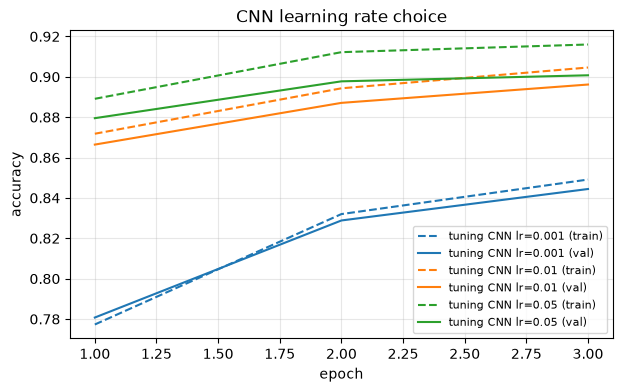

chosen CNN learning rate: 0.05


In [ ]:
CNN_TUNING_EPOCHS = 1 if QUICK_RUN else 3

cnn_lr_candidates = [0.001, 0.01, 0.05]
for lr in cnn_lr_candidates:
  print(f'learning rate {lr}')
  torch.manual_seed(0)
  results[f'tuning CNN lr={lr}'] = {'history': train_model(ConvNet().to(device), trainloader, train_evalloader, valloader,
                                                           num_epochs = CNN_TUNING_EPOCHS, lr = lr)}

plot_histories([f'tuning CNN lr={lr}' for lr in cnn_lr_candidates], 'CNN learning rate choice', eval_name = 'val')
CNN_LR = max(cnn_lr_candidates, key = lambda lr: results[f'tuning CNN lr={lr}']['history']['eval_acc'][-1])
for lr in cnn_lr_candidates:
  del results[f'tuning CNN lr={lr}']
print('chosen CNN learning rate:', CNN_LR)

A learning rate of 0.05 gives the best validation accuracy after 3 epochs (90.1%), just ahead of 0.01 (89.6%), while 0.001 learns too slowly (84.4%). With momentum 0.9, a fairly large step trains this small CNN stably.

### Choosing the number of filters (validation set)

The assignment leaves the convolutional hyperparameters to us. We try three sizes for (conv1, conv2) filters
with the chosen learning rate.

filters (8, 16)
Epoch [1/3] - train acc 0.8827, eval acc 0.8748, training time so far 5s
Epoch [2/3] - train acc 0.8680, eval acc 0.8625, training time so far 10s
Epoch [3/3] - train acc 0.9000, eval acc 0.8864, training time so far 15s
filters (16, 32)
Epoch [1/3] - train acc 0.8891, eval acc 0.8795, training time so far 6s
Epoch [2/3] - train acc 0.9122, eval acc 0.8978, training time so far 12s
Epoch [3/3] - train acc 0.9160, eval acc 0.9008, training time so far 17s
filters (32, 64)
Epoch [1/3] - train acc 0.8867, eval acc 0.8819, training time so far 8s
Epoch [2/3] - train acc 0.9072, eval acc 0.8969, training time so far 15s
Epoch [3/3] - train acc 0.9221, eval acc 0.9003, training time so far 23s


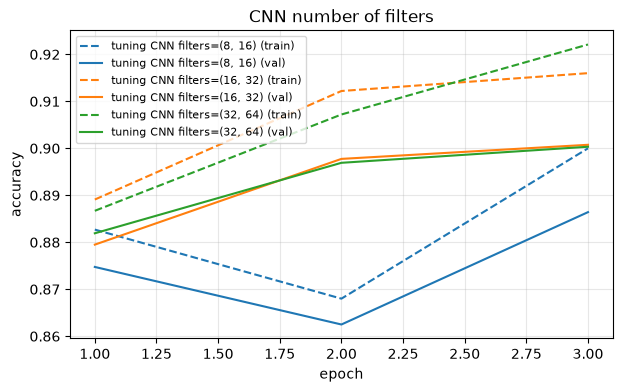

chosen number of filters: (16, 32)


In [ ]:
channel_candidates = [(8, 16), (16, 32), (32, 64)]
for ch in channel_candidates:
  print(f'filters {ch}')
  torch.manual_seed(0)
  results[f'tuning CNN filters={ch}'] = {'history': train_model(ConvNet(channels = ch).to(device), trainloader, train_evalloader, valloader,
                                                                num_epochs = CNN_TUNING_EPOCHS, lr = CNN_LR)}

plot_histories([f'tuning CNN filters={ch}' for ch in channel_candidates], 'CNN number of filters', eval_name = 'val')
CNN_CHANNELS = max(channel_candidates, key = lambda ch: results[f'tuning CNN filters={ch}']['history']['eval_acc'][-1])
for ch in channel_candidates:
  del results[f'tuning CNN filters={ch}']
print('chosen number of filters:', CNN_CHANNELS)

(16, 32) and (32, 64) filters reach the same validation accuracy (90.1% vs. 90.0%), while (8, 16) is lower (88.6%). Doubling the filters adds computation (23 s vs. 17 s) without improving accuracy, so we choose (16, 32).

### Choosing the CNN batch size (validation set)

Same CNN, chosen learning rate and filters. We also record the training time of each batch size.

batch size 32
Epoch [1/3] - train acc 0.8661, eval acc 0.8655, training time so far 8s
Epoch [2/3] - train acc 0.8911, eval acc 0.8779, training time so far 16s
Epoch [3/3] - train acc 0.8942, eval acc 0.8792, training time so far 25s
batch size 64
Epoch [1/3] - train acc 0.8891, eval acc 0.8795, training time so far 6s
Epoch [2/3] - train acc 0.9122, eval acc 0.8978, training time so far 12s
Epoch [3/3] - train acc 0.9160, eval acc 0.9008, training time so far 19s
batch size 128
Epoch [1/3] - train acc 0.8880, eval acc 0.8828, training time so far 6s
Epoch [2/3] - train acc 0.9100, eval acc 0.8976, training time so far 11s
Epoch [3/3] - train acc 0.9161, eval acc 0.9024, training time so far 16s
batch size 256
Epoch [1/3] - train acc 0.8591, eval acc 0.8612, training time so far 4s
Epoch [2/3] - train acc 0.8903, eval acc 0.8824, training time so far 9s
Epoch [3/3] - train acc 0.9099, eval acc 0.9027, training time so far 14s


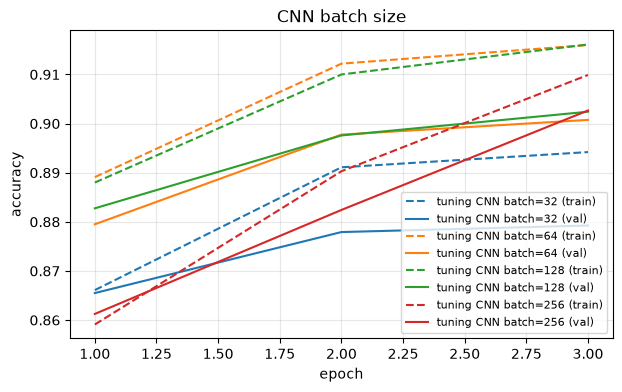

batch size 32: training time 25s
batch size 64: training time 19s
batch size 128: training time 16s
batch size 256: training time 14s
chosen CNN batch size: 256


In [ ]:
cnn_batch_candidates = [32, 64, 128, 256]
for bs in cnn_batch_candidates:
  print(f'batch size {bs}')
  bs_trainloader, bs_train_evalloader, bs_valloader, _ = make_loaders(train_transform, train_transform, batch_size = bs)
  torch.manual_seed(0)
  results[f'tuning CNN batch={bs}'] = {'history': train_model(ConvNet(channels = CNN_CHANNELS).to(device), bs_trainloader,
                                                              bs_train_evalloader, bs_valloader,
                                                              num_epochs = CNN_TUNING_EPOCHS, lr = CNN_LR)}

plot_histories([f'tuning CNN batch={bs}' for bs in cnn_batch_candidates], 'CNN batch size', eval_name = 'val')
for bs in cnn_batch_candidates:
  print(f'batch size {bs}: training time {results[f"tuning CNN batch={bs}"]["history"]["time"]:.0f}s')
CNN_BATCH_SIZE = max(cnn_batch_candidates, key = lambda bs: results[f'tuning CNN batch={bs}']['history']['eval_acc'][-1])
for bs in cnn_batch_candidates:
  del results[f'tuning CNN batch={bs}']
print('chosen CNN batch size:', CNN_BATCH_SIZE)

# rebuild the loaders with the chosen batch size
trainloader, train_evalloader, valloader, testloader = make_loaders(train_transform, train_transform, batch_size = CNN_BATCH_SIZE)
trainloader_aug, _, _, _ = make_loaders(aug_transform, train_transform, batch_size = CNN_BATCH_SIZE)

Batch sizes 64, 128 and 256 are within 0.2 points (90.1-90.3%), and 256 is the most accurate and the fastest (14 s vs. 25 s for 32). Batch size 32 is clearly worse (87.9%), because with a learning rate of 0.05 its smaller batches give noisier gradient steps. We choose 256.

### Choosing the number of CNN epochs (validation set)

One long run with all the chosen settings; we keep the number of epochs with the best validation accuracy.
(The augmented CNN in Q7 uses the same number of epochs, so the two are compared with the same training budget.)

Epoch [1/20] - train acc 0.8591, eval acc 0.8612, training time so far 5s
Epoch [2/20] - train acc 0.8903, eval acc 0.8824, training time so far 9s
Epoch [3/20] - train acc 0.9099, eval acc 0.9027, training time so far 13s
Epoch [4/20] - train acc 0.9155, eval acc 0.9009, training time so far 18s
Epoch [5/20] - train acc 0.9151, eval acc 0.9020, training time so far 22s
Epoch [6/20] - train acc 0.9248, eval acc 0.9093, training time so far 26s
Epoch [7/20] - train acc 0.9359, eval acc 0.9121, training time so far 30s
Epoch [8/20] - train acc 0.9401, eval acc 0.9149, training time so far 35s
Epoch [9/20] - train acc 0.9499, eval acc 0.9178, training time so far 39s
Epoch [10/20] - train acc 0.9452, eval acc 0.9140, training time so far 43s
Epoch [11/20] - train acc 0.9579, eval acc 0.9153, training time so far 48s
Epoch [12/20] - train acc 0.9612, eval acc 0.9203, training time so far 52s
Epoch [13/20] - train acc 0.9609, eval acc 0.9146, training time so far 56s
Epoch [14/20] - train a

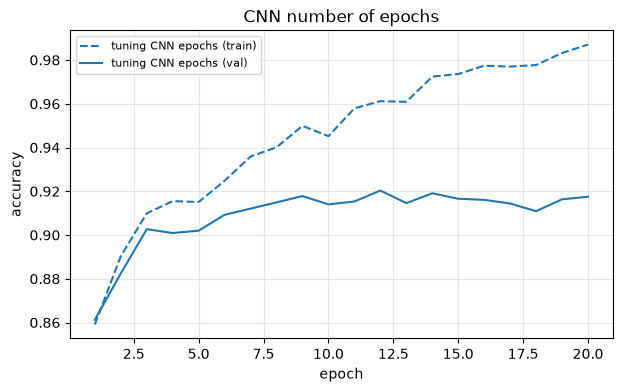

chosen number of CNN epochs: 12


In [ ]:
CNN_MAX_EPOCHS = 1 if QUICK_RUN else 20
torch.manual_seed(0)
results['tuning CNN epochs'] = {'history': train_model(ConvNet(channels = CNN_CHANNELS).to(device), trainloader,
                                                       train_evalloader, valloader, num_epochs = CNN_MAX_EPOCHS, lr = CNN_LR)}
plot_histories(['tuning CNN epochs'], 'CNN number of epochs', eval_name = 'val')
CNN_EPOCHS = int(np.argmax(results['tuning CNN epochs']['history']['eval_acc'])) + 1
del results['tuning CNN epochs']
print('chosen number of CNN epochs:', CNN_EPOCHS)

Validation accuracy peaks at 92.0% at epoch 12 and then fluctuates around 91-92%, while training accuracy keeps rising to 98.7%. The CNN starts to overfit after about 12 epochs, so we train it for 12.

### Training the CNN

Epoch [1/12] - train acc 0.8591, eval acc 0.8435, training time so far 4s
Epoch [2/12] - train acc 0.8903, eval acc 0.8729, training time so far 9s
Epoch [3/12] - train acc 0.9099, eval acc 0.8920, training time so far 13s
Epoch [4/12] - train acc 0.9155, eval acc 0.8919, training time so far 17s
Epoch [5/12] - train acc 0.9151, eval acc 0.8943, training time so far 22s
Epoch [6/12] - train acc 0.9248, eval acc 0.9007, training time so far 27s
Epoch [7/12] - train acc 0.9359, eval acc 0.9044, training time so far 31s
Epoch [8/12] - train acc 0.9401, eval acc 0.9055, training time so far 36s
Epoch [9/12] - train acc 0.9499, eval acc 0.9105, training time so far 40s
Epoch [10/12] - train acc 0.9452, eval acc 0.9047, training time so far 45s
Epoch [11/12] - train acc 0.9579, eval acc 0.9088, training time so far 49s
Epoch [12/12] - train acc 0.9612, eval acc 0.9082, training time so far 54s
CNN test accuracy 0.9082, training time 54s


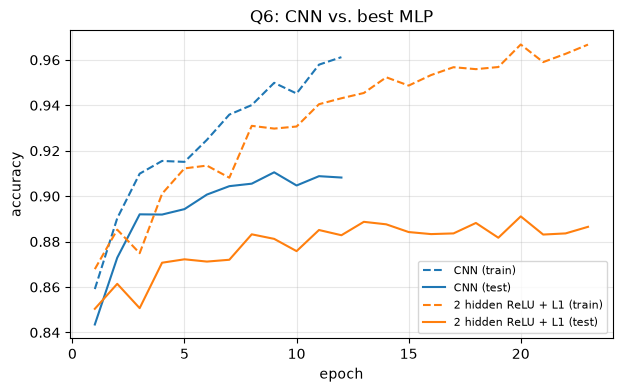

model                                          test acc  time (s)
2 hidden ReLU + L1                               0.8865      44.1
CNN                                              0.9082      53.9


In [ ]:
cnn_models = {}   # model name -> trained CNN (used by the extra experiments)

torch.manual_seed(0)
cnn_models['CNN'] = ConvNet(channels = CNN_CHANNELS).to(device)
history = train_model(cnn_models['CNN'], trainloader, train_evalloader, testloader, num_epochs = CNN_EPOCHS, lr = CNN_LR)
results['CNN'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}
print(f"CNN test accuracy {results['CNN']['test_acc']:.4f}, training time {history['time']:.0f}s")

plot_histories(['CNN', best_mlp], 'Q6: CNN vs. best MLP')
print_table([best_mlp, 'CNN'])

The CNN reaches 90.8% test accuracy, 2.2 points above the best MLP (88.7%), and needs only 12 epochs instead of 23. Its test curve lies above the MLP's from epoch 3 onwards. The CNN is not better because it is bigger: it has more parameters (409k vs. 269k), but most of them sit in the fully connected layer. It is better because its convolutions look at local patches and reuse the same filters at every position, so a pattern learned in one place is recognized everywhere, and pooling tolerates small shifts. The MLP has to learn each pattern separately at every position. Test accuracy is 1.2 points below the validation peak, because the number of epochs was chosen on that validation set. Training times (54 s vs. 44 s) are not directly comparable, since the CNN runs in PyTorch on the GPU and the MLP in NumPy on the CPU.

## Q7: CNN with data augmentation

Same CNN and hyperparameters, trained on the augmented images (`aug_transform` from Q5).

Epoch [1/12] - train acc 0.8149, eval acc 0.8049, training time so far 5s
Epoch [2/12] - train acc 0.8626, eval acc 0.8548, training time so far 9s
Epoch [3/12] - train acc 0.8798, eval acc 0.8681, training time so far 14s
Epoch [4/12] - train acc 0.8684, eval acc 0.8564, training time so far 19s
Epoch [5/12] - train acc 0.8785, eval acc 0.8706, training time so far 23s
Epoch [6/12] - train acc 0.8968, eval acc 0.8842, training time so far 27s
Epoch [7/12] - train acc 0.8903, eval acc 0.8826, training time so far 32s
Epoch [8/12] - train acc 0.8965, eval acc 0.8850, training time so far 37s
Epoch [9/12] - train acc 0.9055, eval acc 0.8873, training time so far 42s
Epoch [10/12] - train acc 0.8983, eval acc 0.8923, training time so far 47s
Epoch [11/12] - train acc 0.9113, eval acc 0.8986, training time so far 52s
Epoch [12/12] - train acc 0.9093, eval acc 0.8965, training time so far 56s
CNN + augmentation test accuracy 0.8965, training time 56s


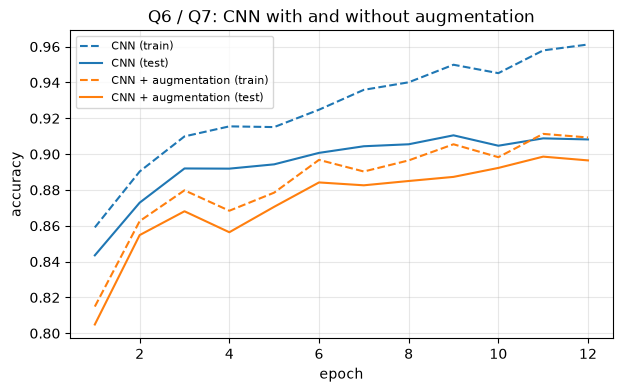

model                                          test acc  time (s)
CNN                                              0.9082      53.9
CNN + augmentation                               0.8965      56.1


In [ ]:
torch.manual_seed(0)
cnn_models['CNN + augmentation'] = ConvNet(channels = CNN_CHANNELS).to(device)
history = train_model(cnn_models['CNN + augmentation'], trainloader_aug, train_evalloader, testloader, num_epochs = CNN_EPOCHS, lr = CNN_LR)
results['CNN + augmentation'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}
print(f"CNN + augmentation test accuracy {results['CNN + augmentation']['test_acc']:.4f}, "
      f"training time {history['time']:.0f}s")

plot_histories(['CNN', 'CNN + augmentation'], 'Q6 / Q7: CNN with and without augmentation')
print_table(['CNN', 'CNN + augmentation'])

With augmentation, test accuracy drops from 90.8% to 89.7%, but overfitting almost disappears: the train-test gap shrinks from about 5 points (96.1% vs. 90.8%) to about 1 point (90.9% vs. 89.7%). The augmented images are harder to fit, so 12 epochs, chosen for the unaugmented CNN, are too few. The augmented model's test accuracy is still rising at the end and would likely benefit from longer training. Speed is essentially unchanged (56 s vs. 54 s), since the transforms run on the data-loading workers and add little cost per epoch.

### Extra 2: a harmful augmentation

Augmentation helps only if the transformed images still look like test images. FashionMNIST items are always upright, so vertical flips and ±90° rotations create images the test set never contains, such as upside-down shoes, and can make classes look alike. We train the CNN, which is faster than our NumPy MLP, with this augmentation and compare it with the Q5 augmentation.


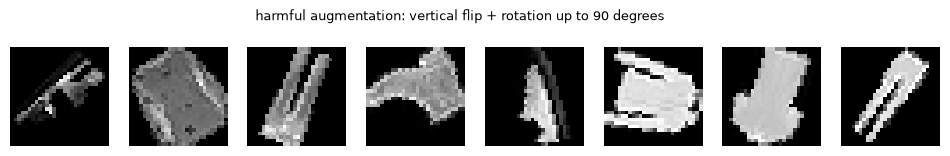

Epoch [1/12] - train acc 0.6908, eval acc 0.6811, training time so far 5s
Epoch [2/12] - train acc 0.7614, eval acc 0.7533, training time so far 10s
Epoch [3/12] - train acc 0.7881, eval acc 0.7784, training time so far 16s
Epoch [4/12] - train acc 0.8114, eval acc 0.8040, training time so far 20s
Epoch [5/12] - train acc 0.8157, eval acc 0.8089, training time so far 24s
Epoch [6/12] - train acc 0.7970, eval acc 0.7893, training time so far 28s
Epoch [7/12] - train acc 0.8407, eval acc 0.8353, training time so far 33s
Epoch [8/12] - train acc 0.8328, eval acc 0.8246, training time so far 37s
Epoch [9/12] - train acc 0.8450, eval acc 0.8357, training time so far 41s
Epoch [10/12] - train acc 0.8515, eval acc 0.8430, training time so far 46s
Epoch [11/12] - train acc 0.8549, eval acc 0.8398, training time so far 50s
Epoch [12/12] - train acc 0.8561, eval acc 0.8442, training time so far 55s


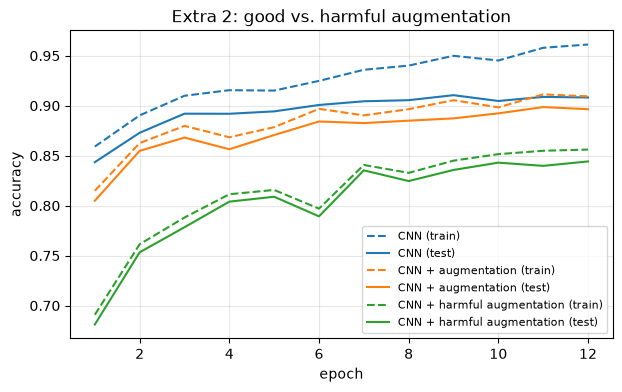

model                                          test acc  time (s)
CNN                                              0.9082      53.9
CNN + augmentation                               0.8965      56.1
CNN + harmful augmentation                       0.8442      54.8


In [ ]:
harmful_augmentation = [transforms.RandomVerticalFlip(), transforms.RandomRotation(90)]
harmful_transform = transforms.Compose(harmful_augmentation + [transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
trainloader_harmful, _, _, _ = make_loaders(harmful_transform, train_transform, batch_size = CNN_BATCH_SIZE)   # validation / test images are NOT changed

# a few training images with the harmful augmentation
images, _ = next(iter(trainloader_harmful))
fig, axes = plt.subplots(1, 8, figsize = (12, 1.8))
for i in range(8):
  axes[i].imshow(images[i, 0], cmap = 'gray'); axes[i].axis('off')
plt.suptitle('harmful augmentation: vertical flip + rotation up to 90 degrees', fontsize = 9)
plt.show()

torch.manual_seed(0)
cnn_models['CNN + harmful augmentation'] = ConvNet(channels = CNN_CHANNELS).to(device)
history = train_model(cnn_models['CNN + harmful augmentation'], trainloader_harmful, train_evalloader, testloader, num_epochs = CNN_EPOCHS, lr = CNN_LR)
results['CNN + harmful augmentation'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

plot_histories(['CNN', 'CNN + augmentation', 'CNN + harmful augmentation'], 'Extra 2: good vs. harmful augmentation')
print_table(['CNN', 'CNN + augmentation', 'CNN + harmful augmentation'])

The harmful augmentation lowers test accuracy to 84.4%, 6.4 points below the CNN without augmentation and 5.2 points below the Q5 augmentation. Training accuracy is also low (85.6%): the model spends its capacity on orientations that never occur in the test set, and upside-down or sideways items become harder to tell apart. This confirms that augmentation helps only when the transformed images still look like real test images.

### Extra 3: where do the best MLP and the best CNN make mistakes?

Confusion matrices (rows = true class, columns = predicted class) and the accuracy of every class.
This shows which classes limit the accuracy and whether the CNN fixes the same mistakes as the MLP.

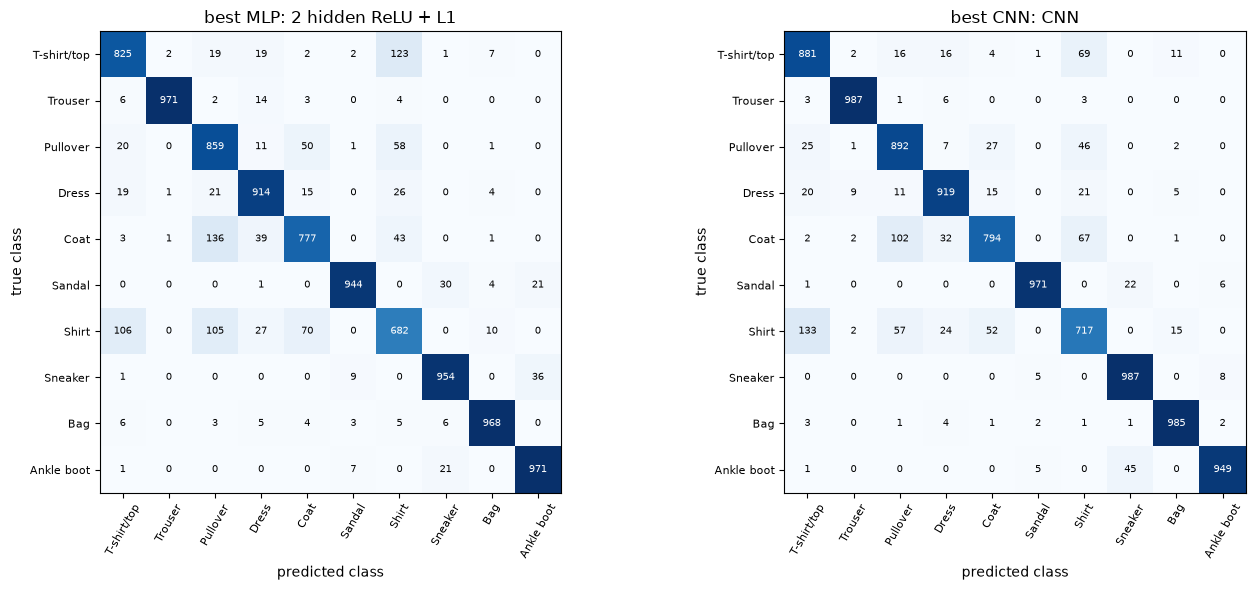

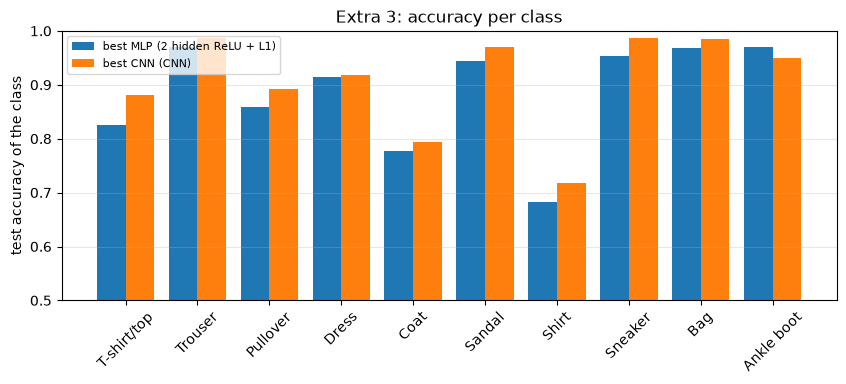

Most common mistakes of the best CNN:
  Shirt        predicted as T-shirt/top : 133 times
  Coat         predicted as Pullover    : 102 times
  T-shirt/top  predicted as Shirt       : 69 times
  Coat         predicted as Shirt       : 67 times
  Shirt        predicted as Pullover    : 57 times


In [ ]:
def confusion_matrix(true, pred, num_classes = 10):
  cm = np.zeros((num_classes, num_classes), dtype = int)
  for t, p in zip(true, pred):
    cm[t, p] += 1
  return cm

best_cnn = max(['CNN', 'CNN + augmentation'], key = lambda n: results[n]['test_acc'])
mlp_true, mlp_pred = y_test, mlp_models[best_mlp].predict(X_test)
cnn_true, cnn_pred = predict_labels(cnn_models[best_cnn], testloader)

fig, axes = plt.subplots(1, 2, figsize = (14, 6))
for ax, title, true, pred in [(axes[0], f'best MLP: {best_mlp}', mlp_true, mlp_pred),
                              (axes[1], f'best CNN: {best_cnn}', cnn_true, cnn_pred)]:
  cm = confusion_matrix(true, pred)
  ax.imshow(cm, cmap = 'Blues')
  for i in range(10):
    for j in range(10):
      ax.text(j, i, cm[i, j], ha = 'center', va = 'center', fontsize = 7,
              color = 'white' if cm[i, j] > cm.max() / 2 else 'black')
  ax.set_xticks(range(10)); ax.set_xticklabels(class_names, rotation = 60, fontsize = 8)
  ax.set_yticks(range(10)); ax.set_yticklabels(class_names, fontsize = 8)
  ax.set_xlabel('predicted class'); ax.set_ylabel('true class'); ax.set_title(title)
plt.tight_layout()
plt.show()

# accuracy of every class
mlp_per_class = [np.mean(mlp_pred[mlp_true == c] == c) for c in range(10)]
cnn_per_class = [np.mean(cnn_pred[cnn_true == c] == c) for c in range(10)]
x = np.arange(10)
plt.figure(figsize = (10, 3.5))
plt.bar(x - 0.2, mlp_per_class, 0.4, label = f'best MLP ({best_mlp})')
plt.bar(x + 0.2, cnn_per_class, 0.4, label = f'best CNN ({best_cnn})')
plt.xticks(x, class_names, rotation = 45)
plt.ylim(0.5, 1); plt.ylabel('test accuracy of the class'); plt.legend(fontsize = 8); plt.grid(axis = 'y', alpha = .3)
plt.title('Extra 3: accuracy per class')
plt.show()

# the 5 most common mistakes of the CNN
cm = confusion_matrix(cnn_true, cnn_pred)
np.fill_diagonal(cm, 0)
print('Most common mistakes of the best CNN:')
for k in np.argsort(cm.ravel())[::-1][:5]:
  t, p = divmod(k, 10)
  print(f'  {class_names[t]:12s} predicted as {class_names[p]:12s}: {cm[t, p]} times')

The CNN beats the best MLP on 9 of the 10 classes, with the largest gains on T-shirt/top (+5.6 points) and pullover (+3.3), while ankle boot is slightly worse. Both models find the same classes hard. Shirt is the worst (68% for the MLP, 72% for the CNN), followed by coat (78%, 79%). The CNN's most common mistakes are all between upper-body garments: shirt predicted as T-shirt (133 times), coat as pullover (102) and T-shirt as shirt (69). Trousers, footwear and bags are above 95% for both models. The remaining errors come from classes that look very similar at 28*28, not from a general weakness of the model.

## Q8: Pre-trained ResNet-18 with new fully connected layers

We load a ResNet-18 pre-trained on ImageNet, keep and **freeze** all its convolutional layers, remove its fully
connected layer and add our own. ResNet-18 expects RGB images normalized with the ImageNet mean / std, and is made for
larger images, so each FashionMNIST image is resized to 64×64, copied into 3 channels and normalized with the
ImageNet statistics. The augmentation is the same `augmentation` list as in Q5.

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
PRETRAINED_SIZE = 64

resnet_steps = [transforms.Resize(PRETRAINED_SIZE),
                transforms.Grayscale(num_output_channels = 3),
                transforms.ToTensor(),
                transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
resnet_transform = transforms.Compose(resnet_steps)
resnet_aug_transform = transforms.Compose(augmentation + resnet_steps)   # Q5 augmentation first

pre_trainloader_aug, pre_train_evalloader, pre_valloader, pre_testloader = make_loaders(resnet_aug_transform, resnet_transform)

In [ ]:
class PretrainedResNet(nn.Module):

  def __init__(self, num_fc_layers = 2, hidden_units = 256, num_classes = 10, unfreeze_last_block = False):
    super(PretrainedResNet, self).__init__()
    resnet = torchvision.models.resnet18(weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1)

    # Keep every layer except the last one (resnet.fc, its only fully connected layer).
    # The output of these layers has shape (N, 512, 1, 1).
    self.features = nn.Sequential(*list(resnet.children())[:-1])

    # Freeze the convolutional layers: their weights are not updated.
    for p in self.features.parameters():
      p.requires_grad = False

    # Extra 4 only: also train the last residual block (layer4 = self.features[7]).
    if unfreeze_last_block:
      for p in self.features[7].parameters():
        p.requires_grad = True

    # New fully connected layers: (num_fc_layers - 1) hidden layers with ReLU, then the output layer.
    layers = []
    in_features = 512
    for i in range(num_fc_layers - 1):
      layers.append(nn.Linear(in_features, hidden_units))
      layers.append(nn.ReLU())
      in_features = hidden_units
    layers.append(nn.Linear(in_features, num_classes))
    self.classifier = nn.Sequential(*layers)

  def forward(self, x):
    x = self.features(x)          # (N, 512, 1, 1)
    x = x.view(x.size(0), -1)     # (N, 512)
    return self.classifier(x)     # (N, 10)

  def train(self, mode = True):
    # model.train() would also update the BatchNorm statistics inside the ResNet.
    # The convolutional part is frozen, so we always keep it in evaluation mode
    # (also when layer4 is fine-tuned in Extra 4: we keep the ImageNet BatchNorm statistics).
    super(PretrainedResNet, self).train(mode)
    self.features.eval()
    return self

m = PretrainedResNet(num_fc_layers = 2)
print(m.classifier)
print(f'Trainable parameters: {sum(p.numel() for p in m.parameters() if p.requires_grad):,}'
      f'  (total {sum(p.numel() for p in m.parameters()):,})')

Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=10, bias=True)
)
Trainable parameters: 133,898  (total 11,310,410)


### Choosing the learning rate of the new layers (validation set)

learning rate 0.001
Epoch [1/2] - train acc 0.8229, eval acc 0.8252, training time so far 19s
Epoch [2/2] - train acc 0.8211, eval acc 0.8252, training time so far 37s
learning rate 0.01
Epoch [1/2] - train acc 0.8354, eval acc 0.8344, training time so far 18s
Epoch [2/2] - train acc 0.8536, eval acc 0.8528, training time so far 36s
learning rate 0.05
Epoch [1/2] - train acc 0.7574, eval acc 0.7560, training time so far 18s
Epoch [2/2] - train acc 0.7698, eval acc 0.7656, training time so far 36s


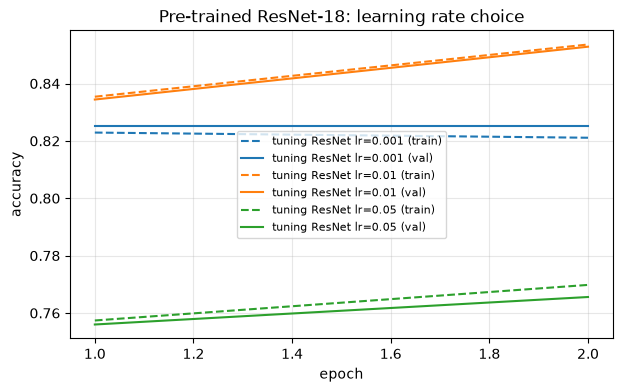

chosen learning rate for the pre-trained model: 0.01


In [ ]:
PRETRAINED_EPOCHS = 1 if QUICK_RUN else 5
PRETRAINED_TUNING_EPOCHS = 1 if QUICK_RUN else 2

pre_lr_candidates = [0.001, 0.01, 0.05]
for lr in pre_lr_candidates:
  print(f'learning rate {lr}')
  torch.manual_seed(0)
  results[f'tuning ResNet lr={lr}'] = {'history': train_model(PretrainedResNet(num_fc_layers = 2).to(device),
                                                              pre_trainloader_aug, pre_train_evalloader, pre_valloader,
                                                              num_epochs = PRETRAINED_TUNING_EPOCHS, lr = lr)}

plot_histories([f'tuning ResNet lr={lr}' for lr in pre_lr_candidates], 'Pre-trained ResNet-18: learning rate choice', eval_name = 'val')
PRETRAINED_LR = max(pre_lr_candidates, key = lambda lr: results[f'tuning ResNet lr={lr}']['history']['eval_acc'][-1])
for lr in pre_lr_candidates:
  del results[f'tuning ResNet lr={lr}']
print('chosen learning rate for the pre-trained model:', PRETRAINED_LR)

A learning rate of 0.01 gives the best validation accuracy after 2 epochs (85.3%). With 0.001 the head barely improves after the first epoch (82.5%), and 0.05 is too large and stays at 76.6%. The best rate is smaller than the CNN's (0.05), because the frozen ResNet features have a different scale than the CNN's learned features.

### How many fully connected layers? (validation set)
We compare 1, 2 and 3 fully connected layers (hidden layers of 256 units); with 1 layer the model is a linear classifier on the frozen ResNet features. We choose by validation accuracy, and the curves also show whether 5 epochs suffice, since only the small head is trained. We keep batch size 64: each ResNet run is expensive, and with a frozen backbone batch size mainly affects speed. Test accuracy is recorded alongside, only for the train/test curves.


===== 1 fully connected layer(s) =====
Epoch [1/5] - train acc 0.7964, eval acc 0.7955, training time so far 18s
Epoch [2/5] - train acc 0.8420, eval acc 0.8456, training time so far 36s
Epoch [3/5] - train acc 0.7994, eval acc 0.7949, training time so far 55s
Epoch [4/5] - train acc 0.8279, eval acc 0.8248, training time so far 73s
Epoch [5/5] - train acc 0.8506, eval acc 0.8435, training time so far 91s
===== 2 fully connected layer(s) =====
Epoch [1/5] - train acc 0.8354, eval acc 0.8344, training time so far 18s
Epoch [2/5] - train acc 0.8533, eval acc 0.8468, training time so far 37s
Epoch [3/5] - train acc 0.8543, eval acc 0.8528, training time so far 55s
Epoch [4/5] - train acc 0.8637, eval acc 0.8625, training time so far 73s
Epoch [5/5] - train acc 0.8656, eval acc 0.8640, training time so far 94s
===== 3 fully connected layer(s) =====
Epoch [1/5] - train acc 0.8384, eval acc 0.8402, training time so far 20s
Epoch [2/5] - train acc 0.8470, eval acc 0.8488, training time so far

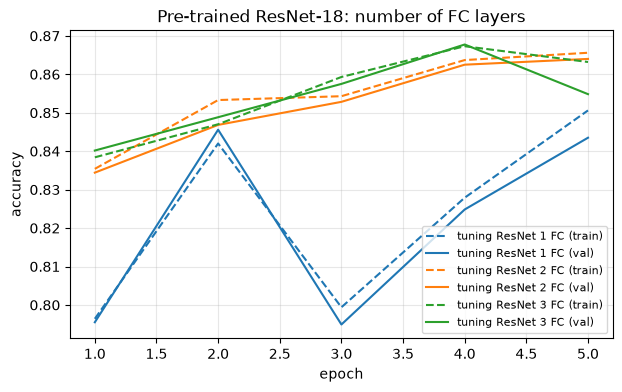

best number of fully connected layers on the validation set: 2


In [ ]:
fc_histories = {}
for num_fc in [1, 2, 3]:
  print(f'===== {num_fc} fully connected layer(s) =====')
  torch.manual_seed(0)
  model = PretrainedResNet(num_fc_layers = num_fc).to(device)
  fc_histories[num_fc] = train_model(model, pre_trainloader_aug, pre_train_evalloader, pre_valloader,
                                     num_epochs = PRETRAINED_EPOCHS, lr = PRETRAINED_LR, testloader = pre_testloader)
  results[f'tuning ResNet {num_fc} FC'] = {'history': fc_histories[num_fc]}

plot_histories([f'tuning ResNet {n} FC' for n in [1, 2, 3]], 'Pre-trained ResNet-18: number of FC layers', eval_name = 'val')
for n in [1, 2, 3]:
  del results[f'tuning ResNet {n} FC']

best_num_fc = max([1, 2, 3], key = lambda n: fc_histories[n]['eval_acc'][-1])
print('best number of fully connected layers on the validation set:', best_num_fc)

With 2 fully connected layers, validation accuracy reaches 86.4% after 5 epochs, against 84.4% for 1 layer and 85.5% for 3 layers. A single linear layer on the frozen features learns unsteadily (its accuracy drops from 84.6% to 79.5% at epoch 3), so one hidden layer is needed to recombine the ImageNet features for clothing. A third layer peaks higher (86.8% at epoch 4) but falls back at epoch 5, so it adds instability rather than a reliable gain. Training and validation accuracy stay within about 1 point for every head, so the model underfits rather than overfits: its accuracy is limited by the frozen features, not by the head's size. We choose 2 layers.

### Test accuracy of the chosen pre-trained model, compared with the best MLP and the CNN

model                                          test acc  time (s)
2 hidden ReLU + L1                               0.8865      44.1
CNN                                              0.9082      53.9
CNN + augmentation                               0.8965      56.1
ResNet-18 + 2 FC                                 0.8597      93.6


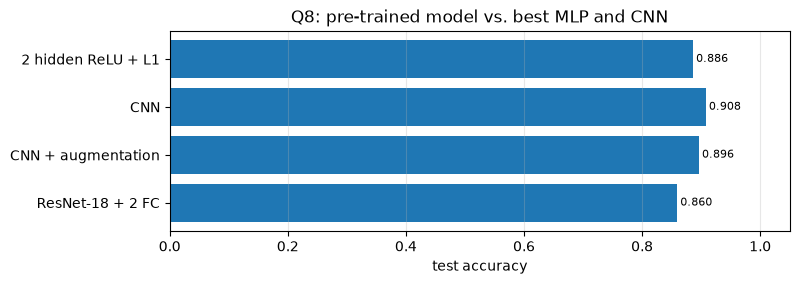

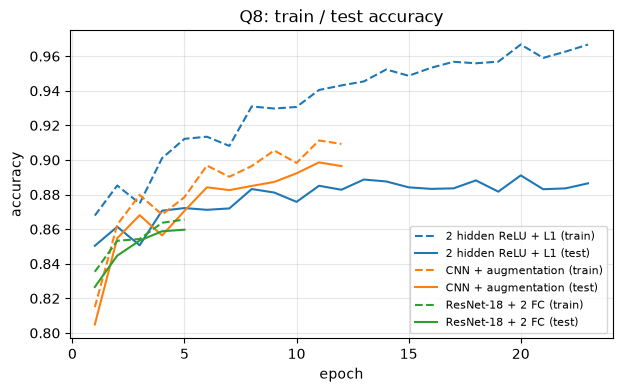

In [ ]:
best_name = f'ResNet-18 + {best_num_fc} FC'
hist = fc_histories[best_num_fc]
results[best_name] = {'test_acc': hist['test_acc'][-1], 'time': hist['time'],
                      'history': {'train_acc': hist['train_acc'], 'eval_acc': hist['test_acc']}}   # test curve for Q10

print_table([best_mlp, 'CNN', 'CNN + augmentation', best_name])
plot_test_acc([best_mlp, 'CNN', 'CNN + augmentation', best_name], 'Q8: pre-trained model vs. best MLP and CNN')
plot_histories([best_mlp, 'CNN + augmentation', best_name], 'Q8: train / test accuracy')

The frozen ResNet-18 with 2 FC layers reaches 86.0% test accuracy, below the best MLP (88.7%), the CNN (90.8%) and the CNN with augmentation (89.7%). It is also the slowest model, at 18.7 s per epoch vs. 4.5 s for the CNN (93.6 s for 5 epochs vs. 53.9 s for 12), even though only 134k of its 11.3M parameters are trained. Every image still passes forward through the whole frozen network, which is more expensive than our small CNN. ImageNet features were learned on large colour photos, so they fit 28×28 grayscale clothing upsampled to 64×64 poorly. On this dataset, a small model trained from scratch is both more accurate and faster. Precomputing the frozen features once would remove most of the training time.

## Q9: The same pre-trained model on CIFAR-10

CIFAR-10 has 60,000 32×32 colour photos in 10 classes (airplane, car, bird, cat, ...), much closer to ImageNet than grayscale clothing. We keep everything else the same: the frozen ResNet-18 with the chosen FC layers, the learning rate, the 64×64 input size, ImageNet normalization and the Q5 augmentation.


Epoch [1/5] - train acc 0.6989, eval acc 0.6790, training time so far 33s
Epoch [2/5] - train acc 0.7212, eval acc 0.7006, training time so far 66s
Epoch [3/5] - train acc 0.7329, eval acc 0.7212, training time so far 99s
Epoch [4/5] - train acc 0.7460, eval acc 0.7284, training time so far 130s
Epoch [5/5] - train acc 0.7524, eval acc 0.7262, training time so far 160s


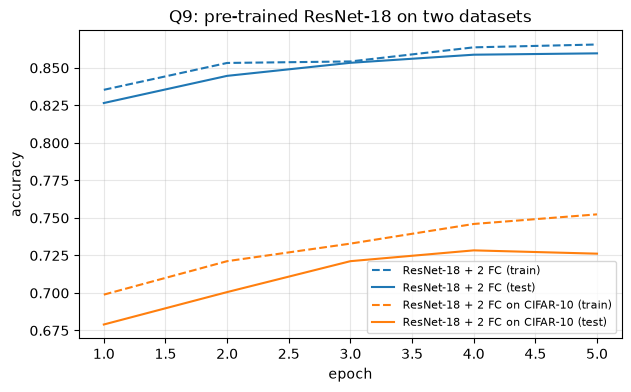

model                                          test acc  time (s)
ResNet-18 + 2 FC                                 0.8597      93.6
ResNet-18 + 2 FC on CIFAR-10                     0.7262     160.1


In [ ]:
cifar_steps = [transforms.Resize(PRETRAINED_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
cifar_train = torchvision.datasets.CIFAR10(root = './data', train = True, download = True,
                                           transform = transforms.Compose(augmentation + cifar_steps))
cifar_test = torchvision.datasets.CIFAR10(root = './data', train = False, download = True,
                                          transform = transforms.Compose(cifar_steps))
if QUICK_RUN:
  cifar_train = torch.utils.data.Subset(cifar_train, range(2000))
  cifar_test = torch.utils.data.Subset(cifar_test, range(500))

cifar_trainloader = DataLoader(cifar_train, batch_size = 64, shuffle = True, num_workers = 2)
cifar_testloader = DataLoader(cifar_test, batch_size = 64, shuffle = False, num_workers = 2)

# 10k training images without augmentation, only to measure the training accuracy (same as train_evalloader)
cifar_train_clean = torchvision.datasets.CIFAR10(root = './data', train = True, download = True,
                                                 transform = transforms.Compose(cifar_steps))
cifar_train_evalloader = DataLoader(torch.utils.data.Subset(cifar_train_clean, range(2000 if QUICK_RUN else 10000)),
                                    batch_size = 64, shuffle = False, num_workers = 2)

torch.manual_seed(0)
cifar_model = PretrainedResNet(num_fc_layers = best_num_fc).to(device)
history = train_model(cifar_model, cifar_trainloader, cifar_train_evalloader, cifar_testloader, num_epochs = PRETRAINED_EPOCHS, lr = PRETRAINED_LR)
results[f'{best_name} on CIFAR-10'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

plot_histories([best_name, f'{best_name} on CIFAR-10'], 'Q9: pre-trained ResNet-18 on two datasets')
print_table([best_name, f'{best_name} on CIFAR-10'])

The same frozen ResNet-18 reaches 72.6% on CIFAR-10, against 86.0% on FashionMNIST. The two accuracies are not directly comparable, because CIFAR-10 is a much harder task: objects vary in pose, colour, scale and background, and several classes are visually close (cat/dog, deer/horse, automobile/truck). On FashionMNIST, the frozen features lose to a small CNN trained from scratch (90.8%), so transfer gives no benefit there. CIFAR-10's colour photos of animals and vehicles are much closer to ImageNet, which suggests its features transfer better, and Extra 4 tests this. Both datasets are upsampled to only 64*64, far below ImageNet's 224*224, so the final ResNet feature maps are just 2*2 and the frozen features are coarse for both. CIFAR-10 test accuracy stops improving after epoch 4 (72.8%) while training accuracy keeps rising slowly, so the frozen head is close to its limit.

### Extra 4: frozen vs. fine-tuned ResNet-18 on both datasets

We expect the frozen ImageNet features to suit CIFAR-10's colour photos better than FashionMNIST's grayscale clothing. If so, also training the last residual block (`layer4`) should help FashionMNIST more than CIFAR-10. Everything else stays the same, except that the learning rate is capped at 0.01, since large steps can destroy pre-trained weights.


Trainable parameters: 8,527,626
Epoch [1/5] - train acc 0.8513, eval acc 0.8459, training time so far 30s
Epoch [2/5] - train acc 0.8943, eval acc 0.8912, training time so far 59s
Epoch [3/5] - train acc 0.8939, eval acc 0.8872, training time so far 89s
Epoch [4/5] - train acc 0.9081, eval acc 0.9046, training time so far 117s
Epoch [5/5] - train acc 0.9070, eval acc 0.9004, training time so far 148s
Epoch [1/5] - train acc 0.7858, eval acc 0.7727, training time so far 42s
Epoch [2/5] - train acc 0.8335, eval acc 0.8172, training time so far 84s
Epoch [3/5] - train acc 0.8397, eval acc 0.8212, training time so far 126s
Epoch [4/5] - train acc 0.8677, eval acc 0.8429, training time so far 168s
Epoch [5/5] - train acc 0.8725, eval acc 0.8411, training time so far 209s
model                                          test acc  time (s)
ResNet-18 + 2 FC                                 0.8597      93.6
ResNet-18 + 2 FC fine-tuned                      0.9004     147.8
ResNet-18 + 2 FC on CIFAR

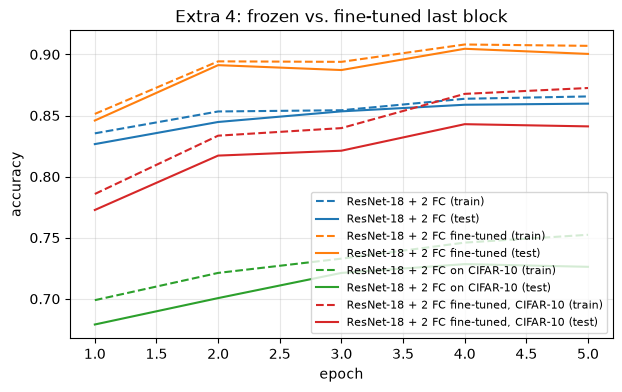

In [ ]:
FINETUNE_LR = min(PRETRAINED_LR, 0.01)
finetuned_name = f'{best_name} fine-tuned'
finetuned_cifar_name = f'{best_name} fine-tuned, CIFAR-10'

torch.manual_seed(0)
finetuned = PretrainedResNet(num_fc_layers = best_num_fc, unfreeze_last_block = True).to(device)
print(f'Trainable parameters: {sum(p.numel() for p in finetuned.parameters() if p.requires_grad):,}')
history = train_model(finetuned, pre_trainloader_aug, pre_train_evalloader, pre_testloader, num_epochs = PRETRAINED_EPOCHS, lr = FINETUNE_LR)
results[finetuned_name] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

torch.manual_seed(0)
finetuned_cifar = PretrainedResNet(num_fc_layers = best_num_fc, unfreeze_last_block = True).to(device)
history = train_model(finetuned_cifar, cifar_trainloader, cifar_train_evalloader, cifar_testloader, num_epochs = PRETRAINED_EPOCHS, lr = FINETUNE_LR)
results[finetuned_cifar_name] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

print_table([best_name, finetuned_name, f'{best_name} on CIFAR-10', finetuned_cifar_name])
for dataset, frozen, tuned in [('FashionMNIST', best_name, finetuned_name),
                               ('CIFAR-10', f'{best_name} on CIFAR-10', finetuned_cifar_name)]:
  gain = results[tuned]['test_acc'] - results[frozen]['test_acc']
  print(f'{dataset:13s} frozen {results[frozen]["test_acc"]:.4f} -> fine-tuned {results[tuned]["test_acc"]:.4f}  (gain {gain:+.4f})')

plot_histories([best_name, finetuned_name, f'{best_name} on CIFAR-10', finetuned_cifar_name],
               'Extra 4: frozen vs. fine-tuned last block')

Fine-tuning the last residual block (`layer4`) helps both datasets: FashionMNIST improves from 86.0% to 90.0% (+4.1 points) and CIFAR-10 from 72.6% to 84.1% (+11.5 points). This contradicts our hypothesis, since CIFAR-10 gains more, also relative to its error rate (error drops by 42% vs. 29%). A better explanation is that the earlier ResNet blocks already extract useful edges, textures and shapes for natural photos, so adapting only the last block turns them into strong CIFAR-10 features. For FashionMNIST, adapting the last block helps but is not enough. The fine-tuned model (90.0%) only matches our small CNN trained from scratch (90.8%), which suggests the earlier ImageNet features are less suited to small grayscale images. Fine-tuning costs about 50% more training time (148 s vs. 94 s, and 209 s vs. 160 s on CIFAR-10) and opens a small train-test gap (about 3 points on CIFAR-10), since it trains 8.5M parameters instead of 134k.

# Summary of all models and Q10

Test accuracy and training time of every model. All training times only count the gradient steps (not the
evaluation after each epoch). The MLPs run in NumPy on the **CPU** while the CNNs and the ResNet run in PyTorch on the
**GPU** (`device`), so times are directly comparable within each group, but across the groups part of the difference
comes from the hardware. Then the train / test accuracy per epoch of the MLPs, the CNNs and
the pre-trained models. These curves show after how many epochs each model starts to overfit
(train accuracy keeps rising while test accuracy stops improving).

model                                          test acc  time (s)
0 hidden                                         0.8348       1.9
1 hidden ReLU                                    0.8858      34.9
2 hidden ReLU                                    0.8789      42.5
2 hidden tanh                                    0.8862      45.4
2 hidden LeakyReLU                               0.8808      45.9
2 hidden ReLU + L1                               0.8865      44.1
2 hidden ReLU + L2                               0.8849      44.4
2 hidden ReLU, unnormalized                      0.1000      30.2
2 hidden ReLU, unnormalized, lr=1e-5             0.7829      40.9
2 hidden ReLU + L2 + augmentation                0.8795      85.6
CNN                                              0.9082      53.9
CNN + augmentation                               0.8965      56.1
CNN + harmful augmentation                       0.8442      54.8
ResNet-18 + 2 FC                                 0.8597      93.6
ResNet-18 

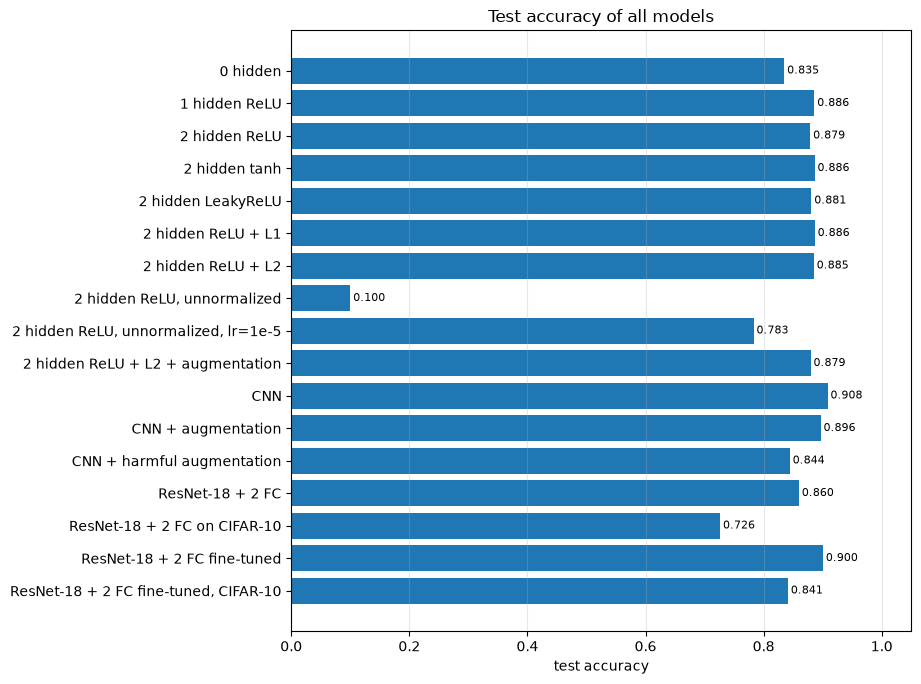

In [ ]:
names = list(results.keys())
print_table(names)
# all times are measured on the same computer, but on different hardware inside it:
print(f'\nTraining times: MLPs = our NumPy code on the CPU, CNNs / ResNet = PyTorch on {device}.')
print('So compare times within each group; across the groups part of the difference is CPU vs. GPU.')
plot_test_acc(names, 'Test accuracy of all models')

The best model on FashionMNIST is the CNN trained from scratch (90.8%), followed by the fine-tuned ResNet-18 (90.0%), the CNN with augmentation (89.7%) and the best MLP (88.7%). The frozen pre-trained model (86.0%) is the weakest of the normalized models with a hidden layer, so transfer from ImageNet only pays off on FashionMNIST once part of the network is fine-tuned. The two largest effects in the whole project are input normalization (10.0% vs. 87.9%) and the choice of architecture (CNN +2.2 points over the MLP). Changing the activation, regularization or MLP width each moved accuracy by less than 1 point. Training times are comparable within each group but not across them, because the MLPs run on the CPU and the PyTorch models on the GPU.

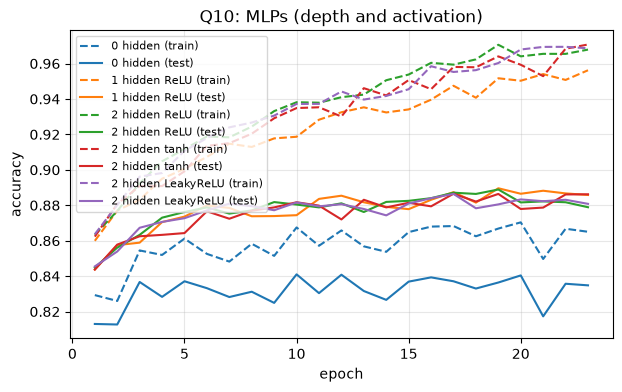

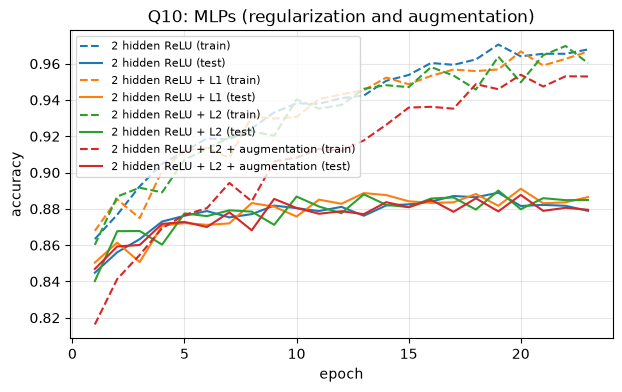

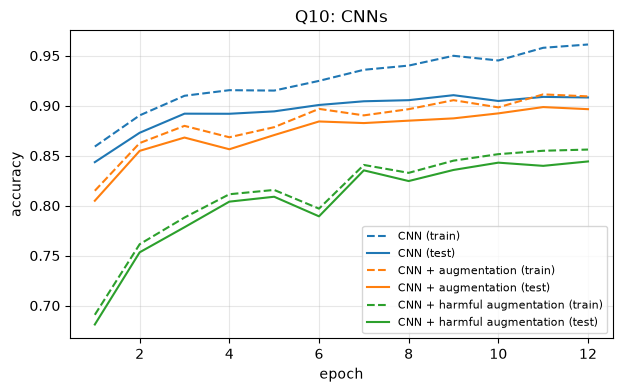

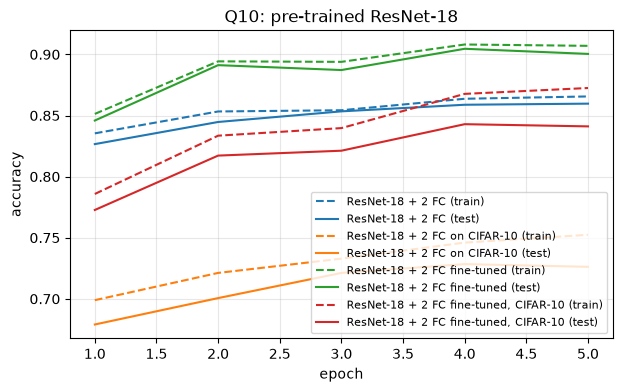

In [ ]:
# Q10: train / test accuracy per epoch
plot_histories(['0 hidden', '1 hidden ReLU', '2 hidden ReLU', '2 hidden tanh', '2 hidden LeakyReLU'], 'Q10: MLPs (depth and activation)')
plot_histories(['2 hidden ReLU', '2 hidden ReLU + L1', '2 hidden ReLU + L2', '2 hidden ReLU + L2 + augmentation'],
               'Q10: MLPs (regularization and augmentation)')
plot_histories(['CNN', 'CNN + augmentation', 'CNN + harmful augmentation'], 'Q10: CNNs')
plot_histories([best_name, f'{best_name} on CIFAR-10', finetuned_name, finetuned_cifar_name], 'Q10: pre-trained ResNet-18')

- **MLPs:** all MLPs with hidden layers overfit. Training accuracy keeps rising to 96–97% while test accuracy plateaus near 88% after about 10 epochs. The linear model underfits instead, with training and test accuracy close together around 84–86%.
- **CNNs:** the CNN overfits less than the MLPs (96.1% train vs. 90.8% test after 12 epochs), and its test accuracy flattens after about 9 epochs. With augmentation, the train and test curves stay within about 1 point, so overfitting nearly disappears, and the model is still improving at epoch 12. The harmful augmentation lowers both curves together, which shows that it makes the training data less useful rather than causing overfitting.
- **Pre-trained ResNet-18:** with the backbone frozen, train and test accuracy stay within about 1 point on FashionMNIST and 3 points on CIFAR-10, so these models underfit and gain little from more epochs. Fine-tuning `layer4` lifts both curves, but on CIFAR-10 a gap of about 3 points opens by epoch 5.

The MLPs and the CNN without augmentation therefore need early stopping around 10 epochs, while the frozen pre-trained models need more capacity, such as fine-tuning, rather than more epochs.